# Geometric Morphometric Anatomical Arm Landmark Quality Control & Class EDA Pipeline### Overview & Scientific ContextGeometric morphometric (GM) landmark data represent **multivariate shape coordinates** (spatial configurations of points in 2D space) rather than simple scalar distance measurements. Consequently, standard univariate statistical quality control methods (such as simple IQR or standard deviation filters on individual coordinates) are insufficient and often misleading.This notebook implements a complete, publication-grade **Geometric Morphometric Quality Control (QC) and Anatomical Arm Wireframe EDA Pipeline** tailored for arm landmark datasets across clinical categories (**SAM**, **MAM**, and **ONC**).---### Primary Anatomical Landmark Anchors:- **LM1**: **Shoulder Point** (Proximal upper arm boundary)- **LM2**: **Elbow Joint Center** (Mid-arm joint pivot)- **LM3**: **Wrist Point** (Distal forearm boundary)- **LM4**: **Armpit / Axilla Point** (Proximal lower arm boundary)### Anatomical Arm Landmark Wireframe Topology:- **Upper Contour (Red)**: `[1, 12, 14, 16, 18, 10, 8, 6, 20]` (Upper arm edge)- **Lower Contour (Blue)**: `[4, 13, 15, 17, 9, 7, 5, 19]` (Lower arm edge)- **Shoulder / Axilla Edge**: `[1, 4]` (Shoulder LM1 to Armpit LM4)- **Wrist Edge**: `[20, 3, 19]` (Upper wrist LM20 to Wrist center LM3 to Lower wrist LM19)- **Midline Axis (Gold)**: `[1 -> 2 -> 3]` (Shoulder LM1 -> Elbow Center LM2 -> Wrist LM3)- **Elbow Joint Cross-Section**: `[18 -> 2 -> 17]` (Upper LM18 through Elbow Center LM2 to Lower LM17)- **Transverse Cross-Sections (Dashed Gray)**: `[12-4, 14-13, 16-15, 18-2-17, 10-9, 8-7, 6-5]`---### Recommended QC & Anatomical Arm Pipeline Workflow:1. **Missing & Invalid Landmark Diagnostics**: Flag incomplete specimens, duplicate rows, non-numeric values, and landmark collapse ($X=Y=0$).2. **Automatic Anatomical Cross-Section Column Repair**: Automatically repair swapped upper/lower landmark pairs in Excel sheets.3. **Generalized Procrustes Analysis (GPA)**: Perform superimposition to eliminate non-shape variation (translation, scaling by Centroid Size, and rotation).4. **Anatomical Horizontal Axis Alignment**: Rotate aligned consensus shapes so the Shoulder-Elbow-Wrist axis lies horizontally ($X$-axis).5. **Procrustes Distance Outlier Detection**: Identify specimens with extreme shape divergence from the consensus arm shape.6. **Principal Component Analysis (PCA) Outlier Detection**: Evaluate major axes of morphological variation and flag isolated shape anomalies in morphospace.7. **Mahalanobis Distance Outlier Detection**: Detect multivariate shape outliers considering inter-landmark covariance structure.8. **Digitizing Error Diagnostics**: Assess scale, bounding box dimensions, and inter-landmark distances (ILDs) using Z-scores and IQR rules.9. **Comprehensive Data Quality Metrics Reporting**: Synthesize all quality indicators into a standardized summary table.10. **Anatomical Arm Class-Based EDA (SAM vs MAM vs ONC)**:   - Anatomical Arm Wireframe Overlay Plots for SAM, MAM, and ONC.   - Vector Displacement Maps showing landmark shifts from ONC baseline.   - Morphological Variance (Procrustes Variance) by class.   - PC Morphospace separation & ANOVA statistical testing.   - Class-based CSV Exports (`class_wise_qc_summary_report.csv`, `class_wise_shape_means.csv`, `class_wise_morphometric_stats.csv`).11. **Final Export of Model Training Datasets**:   - `final_cleaned_dataset_full.csv` (Complete dataset ready for ML pipelines)   - `final_cleaned_dataset_gpa_aligned.csv` (GPA aligned Procrustes shape coordinates)   - `final_cleaned_dataset_pca_features.csv` (PCA feature matrix + Centroid Size + Class_Type)   - `final_cleaned_dataset_raw_repaired.csv` (Anatomically repaired raw coordinates)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2, zscore, f_oneway, kruskal
from sklearn.decomposition import PCA

try:
    from IPython.display import display
except ImportError:
    display = print

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment successfully initialized with SciPy, Scikit-Learn, Pandas, Seaborn, and Matplotlib.")


Environment successfully initialized with SciPy, Scikit-Learn, Pandas, Seaborn, and Matplotlib.


---## Step 1: Check Missing or Invalid Landmarks### Why is this step required?Geometric morphometrics relies on complete, geometrically intact landmark matrices. - **Missing Landmark Values**: Break matrix algebra and alignment routines like Generalized Procrustes Analysis (GPA).- **Duplicate Specimens**: Introduce sample dependency and distort variance calculations.- **Impossible Coordinates**: Coordinates where $X=Y=0$ across multiple landmarks or non-numeric header rows indicate severe annotation errors, file corruption, or failed landmark digitization.

In [2]:
dataset_path = r"e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\outliers_quality_of_data_extraction\global_datasets.xlsx"
df_raw = pd.read_excel(dataset_path)

print(f"Loaded raw dataset shape: {df_raw.shape[0]} specimens, {df_raw.shape[1]} columns.")

# Separate metadata columns from landmark coordinate columns
meta_cols = ['File_Name', 'Individual', 'Class_Type', 'age_month', 'gender']
lm_cols = [c for c in df_raw.columns if c not in meta_cols]

num_landmarks = len(lm_cols) // 2
print(f"Identified {len(lm_cols)} landmark coordinate columns corresponding to {num_landmarks} 2D landmarks (X1, Y1 ... X{num_landmarks}, Y{num_landmarks}).")

# Coerce numeric values for landmark columns
df_cleaned = df_raw.copy()
for col in lm_cols:
    df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')

# 1. Missing Landmarks Count per specimen
df_cleaned['missing_count'] = df_cleaned[lm_cols].isnull().sum(axis=1)

# 2. Duplicate Check
dup_files = df_cleaned.duplicated(subset=['File_Name'], keep=False)
dup_landmarks = df_cleaned.duplicated(subset=lm_cols, keep=False)

# 3. Impossible Coordinates Check (e.g. X=Y=0 for multiple landmarks)
zero_lm_count = (df_cleaned[lm_cols] == 0).sum(axis=1)
df_cleaned['zero_coord_count'] = zero_lm_count

# Summary of initial data hygiene
invalid_rows_mask = (df_cleaned['missing_count'] > 0)
print(f"Total specimens with missing/non-numeric landmarks: {invalid_rows_mask.sum()}")
print(f"Total duplicate File_Name rows: {dup_files.sum()}")
print(f"Total duplicate landmark coordinate rows: {dup_landmarks.sum()}")

# Filter dataset to retain valid numeric specimens for GPA and statistical QC
valid_mask = ~invalid_rows_mask
df_valid = df_cleaned[valid_mask].copy().reset_index(drop=True)
print(f"Retained {len(df_valid)} valid specimens for shape quality control analysis.")


Loaded raw dataset shape: 6625 specimens, 43 columns.
Identified 38 landmark coordinate columns corresponding to 19 2D landmarks (X1, Y1 ... X19, Y19).
Total specimens with missing/non-numeric landmarks: 1
Total duplicate File_Name rows: 0
Total duplicate landmark coordinate rows: 8
Retained 6624 valid specimens for shape quality control analysis.


---## 🔧 Section 2: Geometric Morphometrics Core Functions & Step-by-Step Wireframe Visualizations### Mathematical Foundation of Geometric Morphometrics (GM) & Procrustes SuperimpositionGeometric Morphometrics (GM) analyzes spatial coordinate configurations of anatomical landmarks by partitioning **pure shape variation** from non-shape nuisance variation (**translation**, **scaling**, and **rotation**).#### Under the Hood: The Morphometric ProblemEach specimen's arm configuration is represented as a matrix of 2D pixel landmark coordinates extracted from image contours:$$X = \{(x_1, y_1), (x_2, y_2), \dots, (x_n, y_n)\} \in \mathbb{R}^{n 	imes 2}$$Two arms may share identical biological shape yet yield distinct coordinate matrices $X_1$ and $X_2$ due to camera distance, camera angle/tilt, or image position. GM superimposition mathematically eliminates these non-shape artifacts through a step-by-step transformation pipeline.---### Step-by-Step Shape Normalization Pipeline#### 1️⃣ Step 1: Centering / Translation Removal (Moving Centroid to Origin)First, the algorithm computes the configuration centroid $(ar{X}, ar{Y})$ (arithmetic mean of all landmark coordinates):$$ar{X} = rac{1}{n}\sum_{i=1}^n x_i, \quad ar{Y} = rac{1}{n}\sum_{i=1}^n y_i$$All landmark coordinates are shifted so the centroid lies at origin $(0, 0)$:$$x'_i = x_i - ar{X}, \quad y'_i = y_i - ar{Y}$$$$\mathbf{X_{	ext{centered}}} = \mathbf{X} - \mathbf{1} C^T$$✅ **Effect**: Removes spatial positioning/placement variations of the arm within the image frame.#### 2️⃣ Step 2: Scale Removal (Centroid Size Normalization)Global geometric scale is measured by **Centroid Size ($CS$)**, defined as the Frobenius norm of the centered coordinate matrix:$$CS = \sqrt{\sum_{i=1}^n (x'_i)^2 + (y'_i)^2} = ||\mathbf{X_{	ext{centered}}}||_F$$Every coordinate is normalized by dividing by $CS$:$$x''_i = rac{x'_i}{CS}, \quad y''_i = rac{y'_i}{CS} \implies \mathbf{X_{	ext{scaled}}} = rac{\mathbf{X_{	ext{centered}}}}{CS}$$✅ **Effect**: Removes image scale, camera distance, and phone sensor differences. **No physical ruler or external calibration object is required for diagnosis.**#### 3️⃣ Step 3: Rotation Alignment (Standardizing Orientation)To remove arm tilt, the scaled configuration $\mathbf{X_{	ext{scaled}}}$ is rotated onto a reference shape $\mathbf{Y_{	ext{ref}}}$ by estimating an optimal 2D orthogonal rotation matrix $\mathbf{\Gamma} \in SO(2)$:$$\mathbf{\Gamma} = egin{pmatrix} \cos	heta & \sin	heta \ -\sin	heta & \cos	heta \end{pmatrix}$$The optimal angle $	heta$ minimizes the sum of squared Procrustes distances:$$\min_{\mathbf{\Gamma}} ||\mathbf{X_{	ext{scaled}}} \mathbf{\Gamma} - \mathbf{Y_{	ext{ref}}}||_F^2$$Using Singular Value Decomposition (SVD) on the cross-covariance matrix $\mathbf{H} = \mathbf{X_{	ext{scaled}}}^T \mathbf{Y_{	ext{ref}}} = \mathbf{U} \mathbf{\Sigma} \mathbf{V}^T$, the optimal rotation matrix is computed as $\mathbf{\Gamma} = \mathbf{U} \mathbf{V}^T$.✅ **Effect**: Removes rotational tilt and aligns all arms horizontally along the Shoulder-Elbow-Wrist axis.---### Key Alignment Frameworks: GPA vs fOPA & Alternatives| Alignment Method | Mathematical Rationale | Operational Scope & Use Case || :--- | :--- | :--- || **GPA (Generalized Procrustes Analysis)** | Iteratively aligns all training configurations ($X_1, \dots, X_N$) to an iteratively updated consensus mean shape $ar{\mathbf{M}}$ until convergence ($\Delta < 10^{-7}$). | Used for cohort dataset superimposition, population shape analysis, and model training. || **fOPA (Full Ordinary Procrustes Analysis)** | Computes optimal orthogonal rotation $\mathbf{\Gamma}$, scale factor, and translation to align a single new sample ($X_{	ext{new}}$) directly to a fixed target reference ($RT$, e.g., ONC Mean). | Used for **out-of-sample clinical inference**, aligning new patient arm photos without corrupting the fixed training reference. || **wGPA (Weighted GPA)** | Assigns landmark-specific variance weights during rotational alignment to downweight high-variance semilandmarks. | Robustness against noisy contours by prioritizing stable anatomical anchors (LM1, LM2, LM3, LM4). || **SRVF (Square Root Velocity Framework)** | Aligns shape contours via functional distance minimization using Karcher Mean / Median under elastic metric geometry. | Provides elastic curve matching for complex continuous boundary contours. |---### What Remains After Superimposition? Pure Shape InformationAfter GPA/fOPA normalization, all non-shape noise is suppressed, leaving **pure morphological shape information**:- ✅ **Relative Arm Width & Cross-Sectional Tapering**- ✅ **Contour Curvature along Biceps & Forearm**- ✅ **Inward Retraction of Boundary Semilandmarks**- ✅ **Specific Wasting Patterns (SAM vs MAM vs ONC)**❌ **Removed Artifacts**: Camera distance, pixel dimensions, sensor aspect ratios, device models, and positioning tilt.**Why this enables precise SAM detection**: Severe Acute Malnutrition (SAM) causes distinct geometric changes—boundary semilandmarks collapse inward and cross-sectional width shrinks relative to longitudinal length. GPA/fOPA amplify these underlying geometric signals while eliminating imaging noise.---### Anatomical Wireframe Topology:- **Solid Boundary Lines**: Upper arm contour (`1-12-14-16-18-10-8-6-20`), Lower arm contour (`4-13-15-17-9-7-5-19`), Shoulder edge (`1-4`), Wrist edge (`20-3-19`).- **Dashed Lines**: Transverse cross-sections (`12-4`, `14-13`, `16-15`, `18-17`, `10-9`, `8-7`, `6-5`) & Center midline (`2-3`).

In [3]:
# Define landmark IDs present
landmark_ids = [lid for lid in range(1, 23) if f'X{lid}' in df_valid.columns]
id_to_idx = {lid: i for i, lid in enumerate(landmark_ids)}

# Primary Anatomical Anchors: LM1=Shoulder, LM2=Elbow Center, LM3=Wrist, LM4=Armpit/Axilla
primary_landmarks = {
    1: 'Shoulder (LM1)',
    2: 'Elbow Center (LM2)',
    3: 'Wrist (LM3)',
    4: 'Armpit/Axilla (LM4)'
}

# Wireframe Contour Indices according to specified topology
upper_contour_ids = [1, 12, 14, 16, 18, 10, 8, 6, 20]
upper_contour_idx = [id_to_idx[lid] for lid in upper_contour_ids if lid in id_to_idx]

lower_contour_ids = [4, 13, 15, 17, 9, 7, 5, 19]
lower_contour_idx = [id_to_idx[lid] for lid in lower_contour_ids if lid in id_to_idx]

shoulder_edge_ids = [1, 4]
shoulder_edge_idx = [id_to_idx[lid] for lid in shoulder_edge_ids if lid in id_to_idx]

wrist_edge_ids = [20, 3, 19]
wrist_edge_idx = [id_to_idx[lid] for lid in wrist_edge_ids if lid in id_to_idx]

# Transverse cross sections: 12-4, 14-13, 16-15, 18-17, 10-9, 8-7, 6-5
dashed_cross_ids = [[12, 4], [14, 13], [16, 15], [18, 17], [10, 9], [8, 7], [6, 5]]
dashed_cross_idx = [[id_to_idx[lid] for lid in seg if lid in id_to_idx] for seg in dashed_cross_ids]

# Center Midline: 2-3
midline_ids = [2, 3]
midline_idx = [id_to_idx[lid] for lid in midline_ids if lid in id_to_idx]

# Construct 3D Shape Matrix (N specimens, K landmarks, 2 dimensions)
N = len(df_valid)
K = len(landmark_ids)
shapes_raw = np.zeros((N, K, 2))

for i in range(N):
    for lid_idx, lid in enumerate(landmark_ids):
        shapes_raw[i, lid_idx, 0] = df_valid.iloc[i][f'X{lid}']
        shapes_raw[i, lid_idx, 1] = df_valid.iloc[i][f'Y{lid}']

# Detection & Removal of Inverted / Swapped Samples (No Repair to Avoid Distortion)
cross_pairs = [(12, 4), (14, 13), (16, 15), (18, 17), (10, 9), (8, 7), (6, 5)]
inverted_mask = np.zeros(N, dtype=bool)

for idx in range(N):
    for u, l in cross_pairs:
        if u in id_to_idx and l in id_to_idx:
            u_idx, l_idx = id_to_idx[u], id_to_idx[l]
            # If upper Y coordinate is below lower Y coordinate, flag as inverted outlier
            if shapes_raw[idx, u_idx, 1] < shapes_raw[idx, l_idx, 1]:
                inverted_mask[idx] = True
                break

num_inverted = int(inverted_mask.sum())
repaired_count = 0
print(f"Anatomical Hygiene Check: Identified {num_inverted} inverted/swapped specimens. Dropping them to prevent shape distortion.")

# Drop inverted specimens
df_valid = df_valid[~inverted_mask].copy().reset_index(drop=True)
shapes_raw = shapes_raw[~inverted_mask]
N = len(df_valid)
print(f"Retained {N} valid specimens for 5-stage Geometric Morphometrics shape transformation pipeline.")

# Core Function: Arm Wireframe Plotter with Multi-Shape and Single-Shape Support
def plot_arm_wireframe(ax, shapes, color='black', alpha_solid=0.8, alpha_dashed=0.4, 
                       lw_solid=1.5, lw_dashed=1.0, alpha_scatter=0.6, s=20, 
                       label=None, show_labels=True, monochrome=True):
    shapes_arr = np.asarray(shapes)
    if shapes_arr.ndim == 2:
        shapes_arr = shapes_arr[np.newaxis, :, :] # (1, K, 2)
    elif shapes_arr.ndim == 3:
        if shapes_arr.shape[1] == 2 and shapes_arr.shape[0] != 2:
            shapes_arr = np.transpose(shapes_arr, (2, 0, 1))

    N_samples = shapes_arr.shape[0]
    c_upper = color if monochrome else 'red'
    c_lower = color if monochrome else 'blue'
    c_shoulder = color if monochrome else 'purple'
    c_wrist = color if monochrome else 'green'
    c_cross = color if monochrome else 'gray'
    c_midline = color if monochrome else 'gold'

    # 1. Scatter landmark points
    if alpha_scatter > 0 and s > 0:
        all_x = shapes_arr[:, :, 0].flatten()
        all_y = shapes_arr[:, :, 1].flatten()
        ax.scatter(all_x, all_y, color=color, alpha=alpha_scatter, s=s, zorder=3, label=label if label else None)

    # 2. Draw Wireframe Connections
    for i in range(N_samples):
        sh = shapes_arr[i]
        
        # Solid Upper Contour (1-12-14-16-18-10-8-6-20)
        if upper_contour_idx:
            ax.plot(sh[upper_contour_idx, 0], sh[upper_contour_idx, 1], color=c_upper, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5,
                    label=label if (label and i==0 and (alpha_scatter==0 or s==0)) else None)
        
        # Solid Lower Contour (4-13-15-17-9-7-5-19)
        if lower_contour_idx:
            ax.plot(sh[lower_contour_idx, 0], sh[lower_contour_idx, 1], color=c_lower, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        
        # Shoulder Edge (1-4)
        if shoulder_edge_idx:
            ax.plot(sh[shoulder_edge_idx, 0], sh[shoulder_edge_idx, 1], color=c_shoulder, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
            
        # Wrist Edge (20-3-19)
        if wrist_edge_idx:
            ax.plot(sh[wrist_edge_idx, 0], sh[wrist_edge_idx, 1], color=c_wrist, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
            
        # Dashed Transverse Cross-Sections (12-4, 14-13, 16-15, 18-17, 10-9, 8-7, 6-5)
        for seg in dashed_cross_idx:
            ax.plot(sh[seg, 0], sh[seg, 1], color=c_cross, 
                    alpha=alpha_dashed, linewidth=lw_dashed, linestyle='--', zorder=4)
            
        # Center Midline (2-3)
        if len(midline_idx) >= 2:
            ax.plot(sh[midline_idx, 0], sh[midline_idx, 1], color=c_midline, 
                    alpha=alpha_solid * 0.8, linewidth=lw_dashed, linestyle=':', zorder=4)

    # 3. Annotate Landmark Numbers & Primary Anchors
    if show_labels:
        ref_shape = np.mean(shapes_arr, axis=0) if N_samples > 1 else shapes_arr[0]
        for lid in landmark_ids:
            idx = id_to_idx[lid]
            label_text = f"LM{lid}" if lid not in primary_landmarks else f"LM{lid} ({primary_landmarks[lid].split()[0]})"
            ax.text(ref_shape[idx, 0], ref_shape[idx, 1] + 0.015, label_text, 
                    fontsize=8, fontweight='bold', color='black', ha='center', zorder=10)

print("Anatomical Arm Wireframe core plotter function defined.")


Anatomical Hygiene Check: Identified 3 inverted/swapped specimens. Dropping them to prevent shape distortion.
Retained 6621 valid specimens for 5-stage Geometric Morphometrics shape transformation pipeline.
Anatomical Arm Wireframe core plotter function defined.


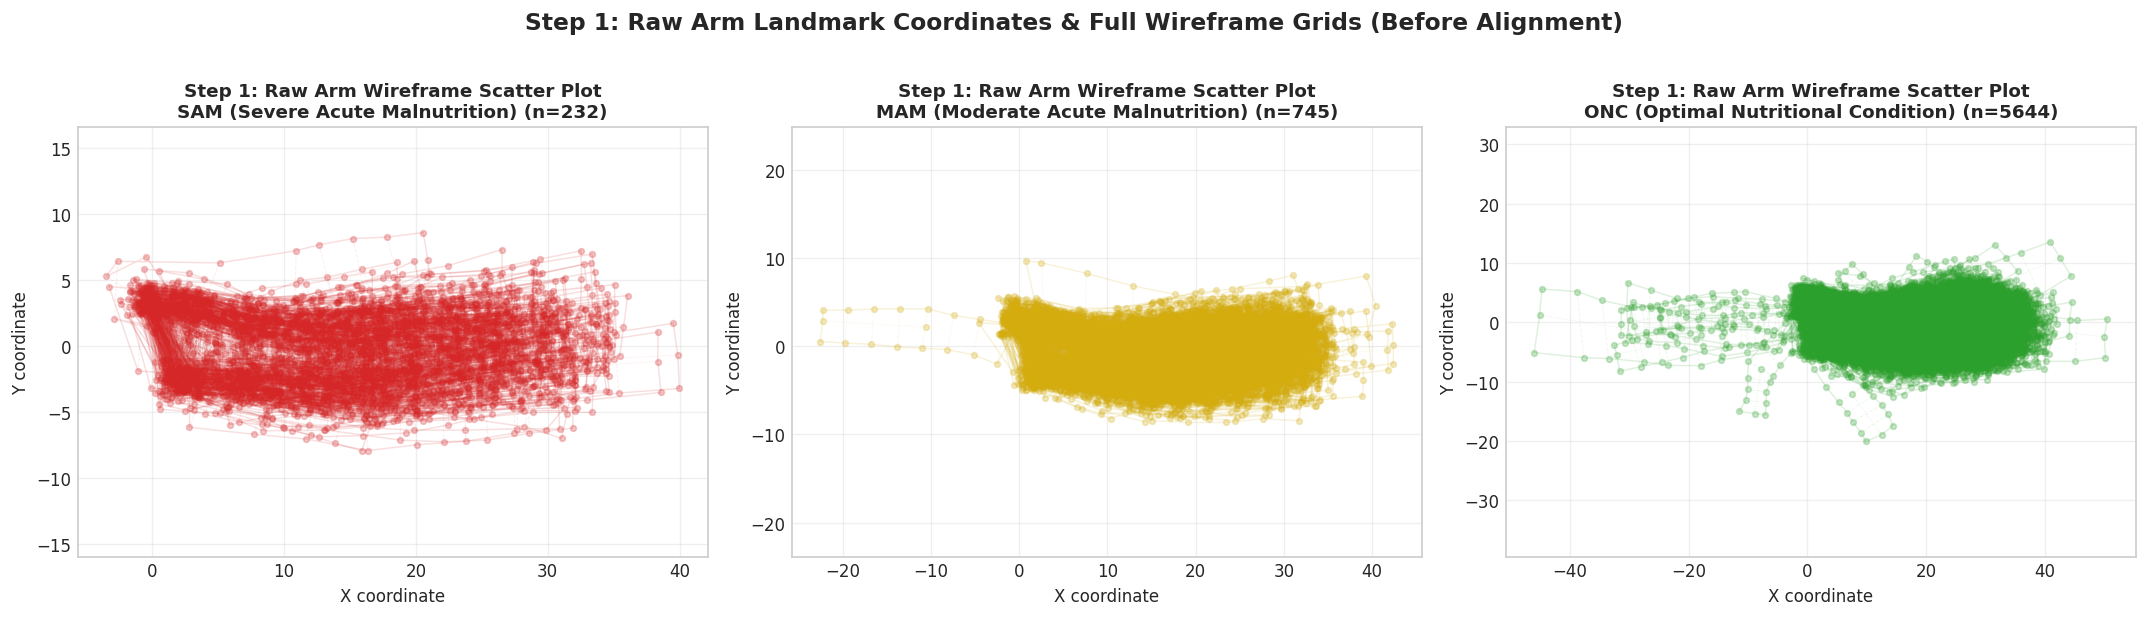

In [4]:
# STEP 1: Raw Landmark Scatter Plot & Arm Wireframes (Before Alignment)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
classes = ['sam', 'mam', 'onc']
titles = ['SAM (Severe Acute Malnutrition)', 'MAM (Moderate Acute Malnutrition)', 'ONC (Optimal Nutritional Condition)']
class_colors = {'sam': '#d62728', 'mam': '#d4ac0d', 'onc': '#2ca02c'}

true_class = df_valid['Class_Type'].values

for ax, cls, title in zip(axes, classes, titles):
    indices = np.where(true_class == cls)[0]
    plot_arm_wireframe(ax, shapes_raw[indices], color=class_colors[cls], 
                       alpha_solid=0.15, alpha_dashed=0.08, lw_solid=0.9, lw_dashed=0.6, alpha_scatter=0.25, s=12, show_labels=False)
    ax.set_title(f'Step 1: Raw Arm Wireframe Scatter Plot\n{title} (n={len(indices)})', fontsize=11, fontweight='bold')
    ax.set_xlabel('X coordinate')
    ax.set_ylabel('Y coordinate')
    ax.grid(True, alpha=0.3)
    ax.axis('equal')

plt.suptitle('Step 1: Raw Arm Landmark Coordinates & Full Wireframe Grids (Before Alignment)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


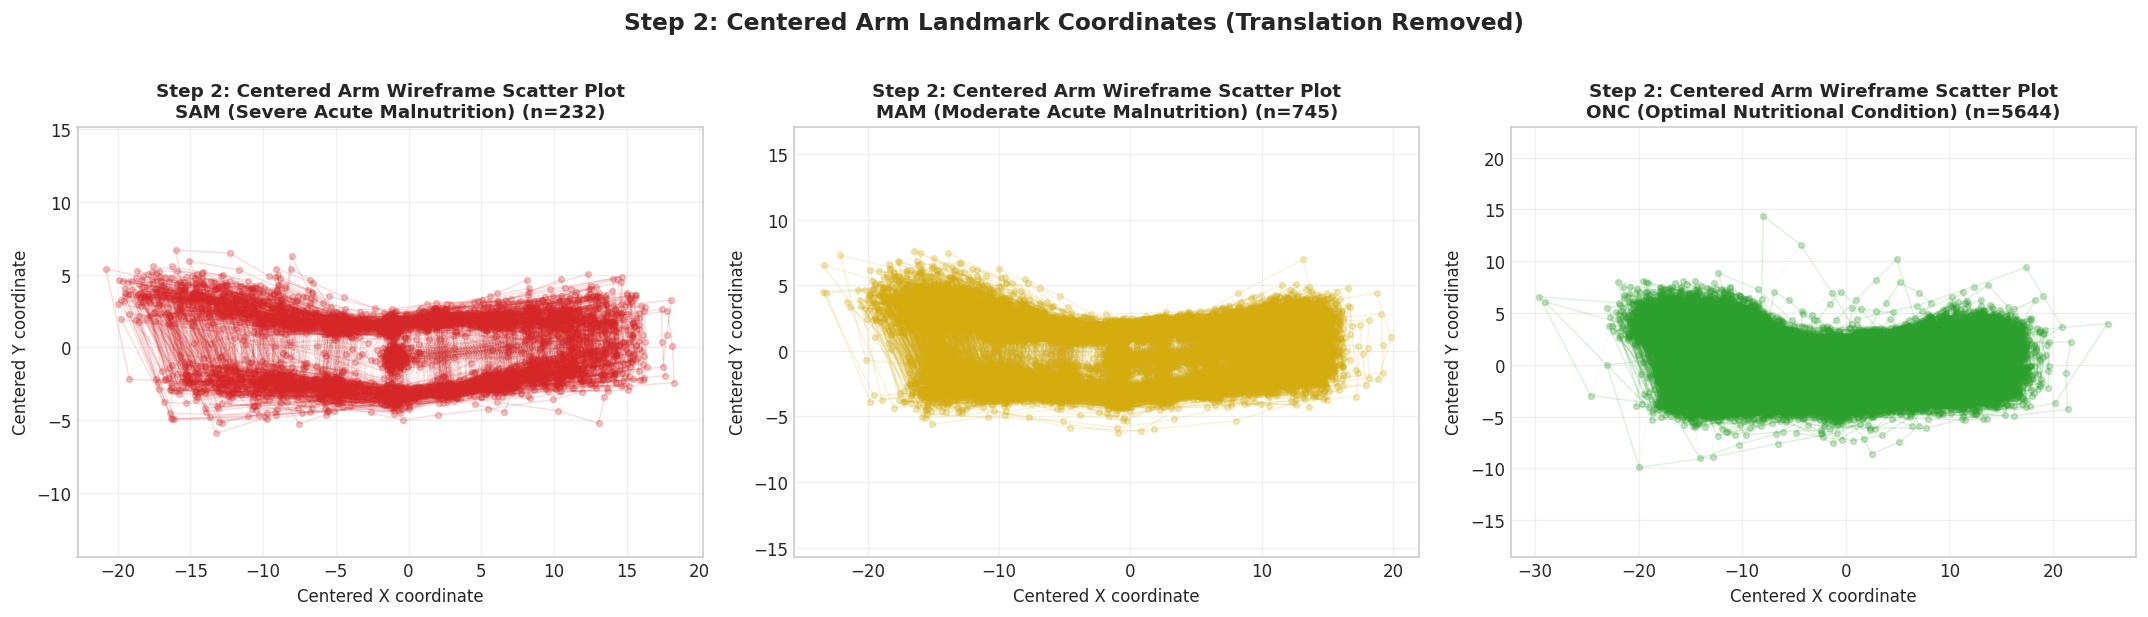

In [5]:
# STEP 2: Centered Landmark Scatter Plots (Translation Removed)
centroids_step2 = np.mean(shapes_raw, axis=1, keepdims=True)
shapes_centered_step2 = shapes_raw - centroids_step2

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, cls, title in zip(axes, classes, titles):
    indices = np.where(true_class == cls)[0]
    plot_arm_wireframe(ax, shapes_centered_step2[indices], color=class_colors[cls], 
                       alpha_solid=0.15, alpha_dashed=0.08, lw_solid=0.9, lw_dashed=0.6, alpha_scatter=0.25, s=12, show_labels=False)
    ax.set_title(f'Step 2: Centered Arm Wireframe Scatter Plot\n{title} (n={len(indices)})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Centered X coordinate')
    ax.set_ylabel('Centered Y coordinate')
    ax.grid(True, alpha=0.3)
    ax.axis('equal')

plt.suptitle('Step 2: Centered Arm Landmark Coordinates (Translation Removed)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


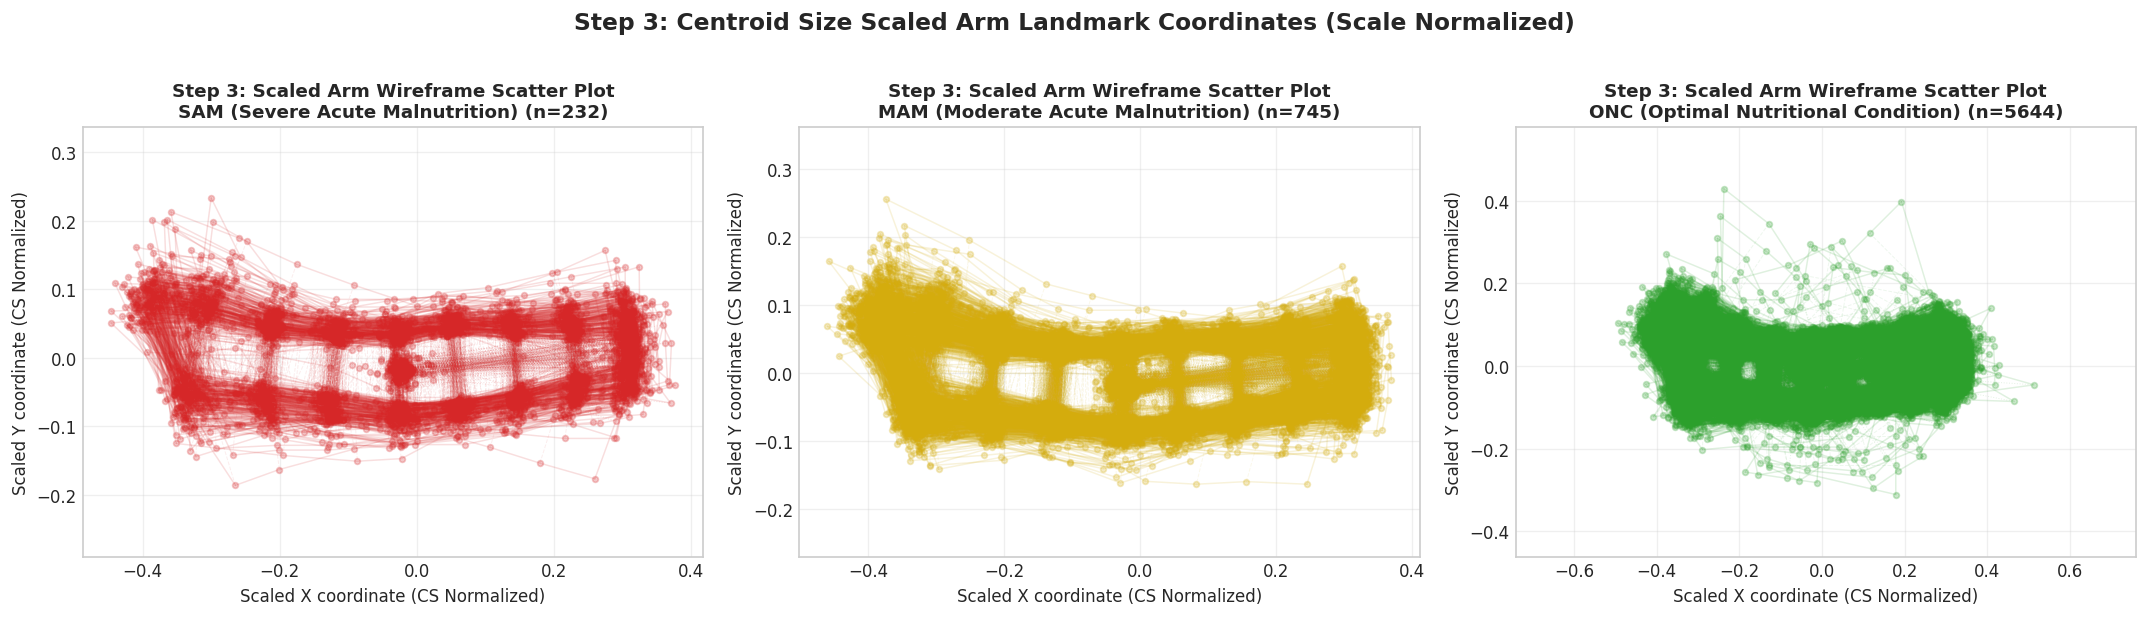

In [6]:
# STEP 3: Scaled Landmark Scatter Plots (Centroid Size Normalized)
cs_step3 = np.linalg.norm(shapes_centered_step2, axis=(1, 2))
df_valid['Centroid_Size'] = cs_step3
shapes_scaled_step3 = shapes_centered_step2 / cs_step3[:, None, None]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, cls, title in zip(axes, classes, titles):
    indices = np.where(true_class == cls)[0]
    plot_arm_wireframe(ax, shapes_scaled_step3[indices], color=class_colors[cls], 
                       alpha_solid=0.15, alpha_dashed=0.08, lw_solid=0.9, lw_dashed=0.6, alpha_scatter=0.25, s=12, show_labels=False)
    ax.set_title(f'Step 3: Scaled Arm Wireframe Scatter Plot\n{title} (n={len(indices)})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Scaled X coordinate (CS Normalized)')
    ax.set_ylabel('Scaled Y coordinate (CS Normalized)')
    ax.grid(True, alpha=0.3)
    ax.axis('equal')

plt.suptitle('Step 3: Centroid Size Scaled Arm Landmark Coordinates (Scale Normalized)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


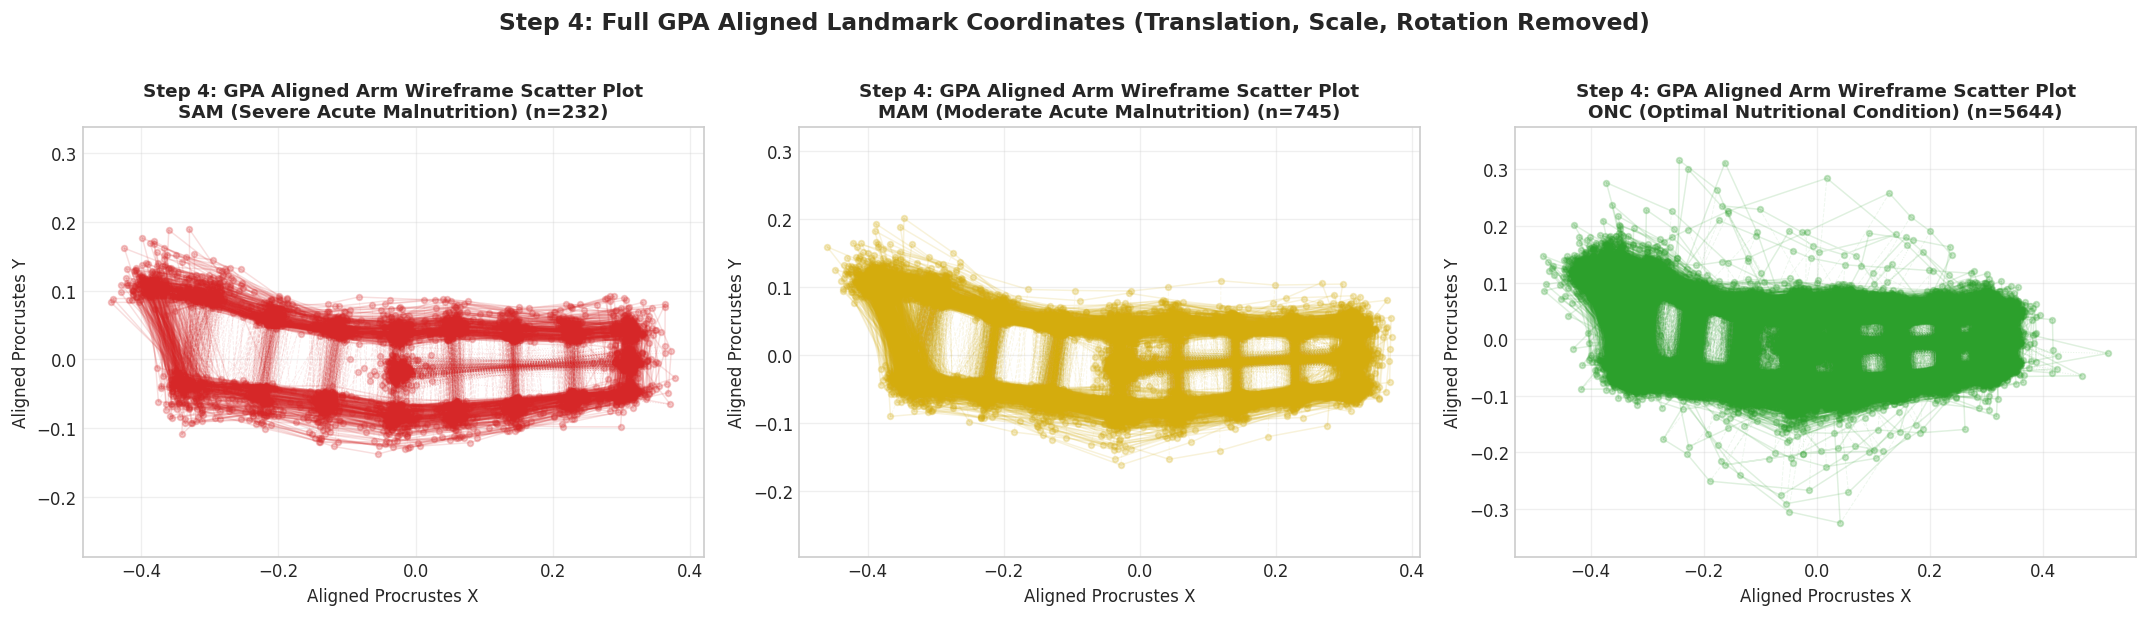

In [7]:
# STEP 4: Full GPA Aligned Landmark Scatter Plots (Translation, Scale, Rotation Removed)
aligned_step4 = shapes_scaled_step3.copy()
mean_shape_step4 = np.mean(aligned_step4, axis=0)
mean_shape_step4 /= np.linalg.norm(mean_shape_step4)

gpa_converged = False
gpa_iterations = 0
max_iter = 50
tolerance = 1e-7

for iter_idx in range(max_iter):
    gpa_iterations += 1
    new_aligned = np.zeros_like(aligned_step4)
    for i in range(N):
        H = aligned_step4[i].T @ mean_shape_step4
        U, S, Vt = np.linalg.svd(H)
        R = U @ Vt
        if np.linalg.det(R) < 0:
            Vt[-1, :] *= -1
            R = U @ Vt
        new_aligned[i] = aligned_step4[i] @ R
    
    new_mean = np.mean(new_aligned, axis=0)
    new_mean /= np.linalg.norm(new_mean)
    diff = np.linalg.norm(new_mean - mean_shape_step4)
    aligned_step4 = new_aligned
    mean_shape_step4 = new_mean
    if diff < tolerance:
        gpa_converged = True
        break

# Rotate horizontally parallel to Shoulder (LM1) -> Wrist (LM20) axis
sh_idx = id_to_idx[1]
wr_idx = id_to_idx[20]
vec = mean_shape_step4[wr_idx] - mean_shape_step4[sh_idx]
theta = np.arctan2(vec[1], vec[0])
R_horiz = np.array([[np.cos(-theta), -np.sin(-theta)], [np.sin(-theta), np.cos(-theta)]])

aligned_horiz = np.zeros_like(aligned_step4)
for i in range(N):
    aligned_horiz[i] = aligned_step4[i] @ R_horiz

mean_shape_horiz = mean_shape_step4 @ R_horiz
mean_shape_horiz -= np.mean(mean_shape_horiz, axis=0)

# Save GPA aligned coordinates to dataframe
for lid in landmark_ids:
    idx = id_to_idx[lid]
    df_valid[f'GPA_X{lid}'] = aligned_horiz[:, idx, 0]
    df_valid[f'GPA_Y{lid}'] = aligned_horiz[:, idx, 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, cls, title in zip(axes, classes, titles):
    indices = np.where(true_class == cls)[0]
    plot_arm_wireframe(ax, aligned_horiz[indices], color=class_colors[cls], 
                       alpha_solid=0.15, alpha_dashed=0.08, lw_solid=0.9, lw_dashed=0.6, alpha_scatter=0.25, s=12, show_labels=False)
    ax.set_title(f'Step 4: GPA Aligned Arm Wireframe Scatter Plot\n{title} (n={len(indices)})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Aligned Procrustes X')
    ax.set_ylabel('Aligned Procrustes Y')
    ax.grid(True, alpha=0.3)
    ax.axis('equal')

plt.suptitle('Step 4: Full GPA Aligned Landmark Coordinates (Translation, Scale, Rotation Removed)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


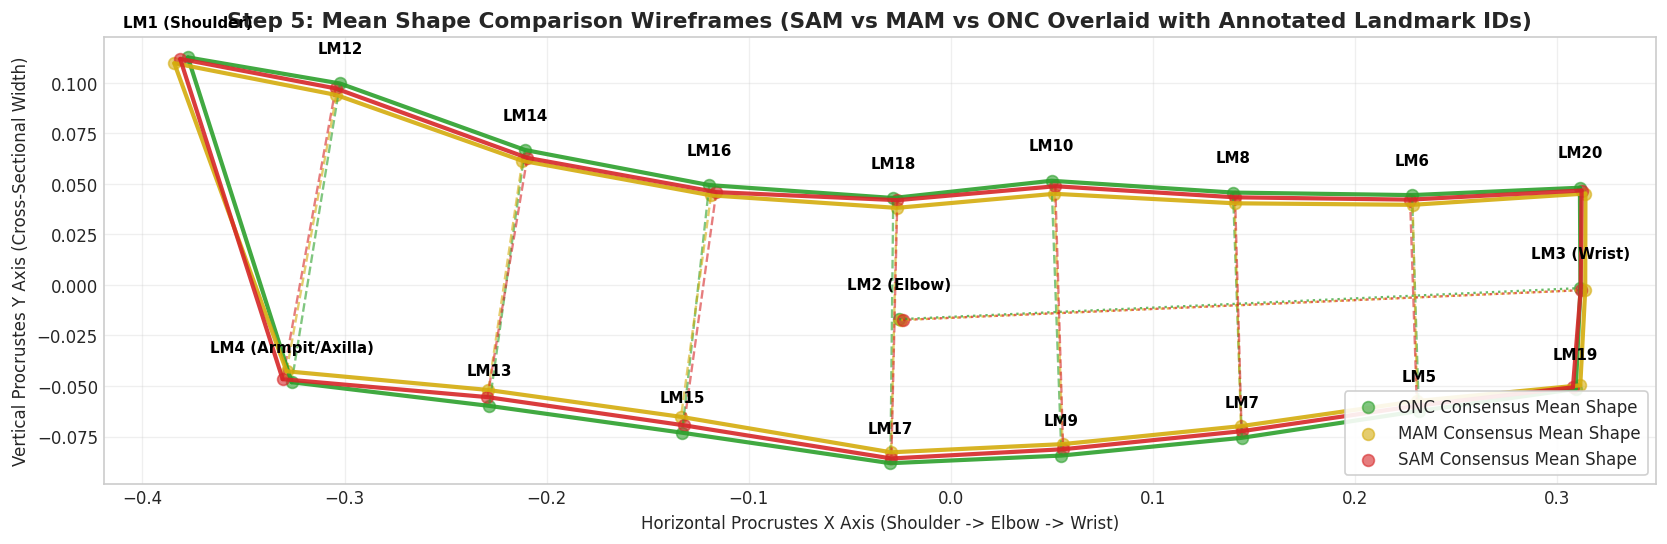

In [8]:
# STEP 5: Mean Shape Comparison Wireframes (SAM vs MAM vs ONC Overlaid with Annotated Landmark IDs)
mean_shapes_step5 = {}
for cls in classes:
    indices = np.where(true_class == cls)[0]
    mean_shapes_step5[cls] = np.mean(aligned_horiz[indices], axis=0)

fig, ax = plt.subplots(figsize=(14, 6))

for cls in ['onc', 'mam', 'sam']:
    plot_arm_wireframe(ax, mean_shapes_step5[cls], color=class_colors[cls], 
                       label=f"{cls.upper()} Consensus Mean Shape", alpha_solid=0.9, alpha_dashed=0.6, lw_solid=2.5, lw_dashed=1.4, s=50, show_labels=False)

# Annotate all landmark IDs on ONC baseline mean shape
onc_mean = mean_shapes_step5['onc']
for lid in landmark_ids:
    idx = id_to_idx[lid]
    l_text = f"LM{lid}" if lid not in primary_landmarks else f"LM{lid} ({primary_landmarks[lid].split()[0]})"
    ax.text(onc_mean[idx, 0], onc_mean[idx, 1] + 0.015, l_text, 
            fontsize=9, fontweight='bold', color='black', ha='center', zorder=10)

ax.set_title("Step 5: Mean Shape Comparison Wireframes (SAM vs MAM vs ONC Overlaid with Annotated Landmark IDs)", fontsize=13, fontweight='bold')
ax.set_xlabel("Horizontal Procrustes X Axis (Shoulder -> Elbow -> Wrist)")
ax.set_ylabel("Vertical Procrustes Y Axis (Cross-Sectional Width)")
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
ax.grid(True, alpha=0.3)
ax.set_aspect('equal')

plt.tight_layout()
plt.show()


---## Step 4: Procrustes Distance Outlier Detection### Why is this step required?After GPA superimposition, the **Procrustes Distance** measures the total shape distance of each specimen from the population mean (consensus) shape:$$d_i = ||X_{i, 	ext{aligned}} - ar{M}||_F = \sqrt{\sum_{k=1}^K ((x_{i,k} - ar{x}_k)^2 + (y_{i,k} - ar{y}_k)^2)}$$Specimens with extreme Procrustes distances ($> 	ext{Mean} + 3 	imes 	ext{Std}$) represent severe shape anomalies, landmark misplacements, inverted annotations, or mislabelled biological samples.

Procrustes Distance Metrics: Mean = 0.0773, Std = 0.0459
Procrustes Distance Outlier Threshold (Mean + 3SD): 0.2151
Identified Procrustes Shape Outliers: 48 specimens (0.72%).


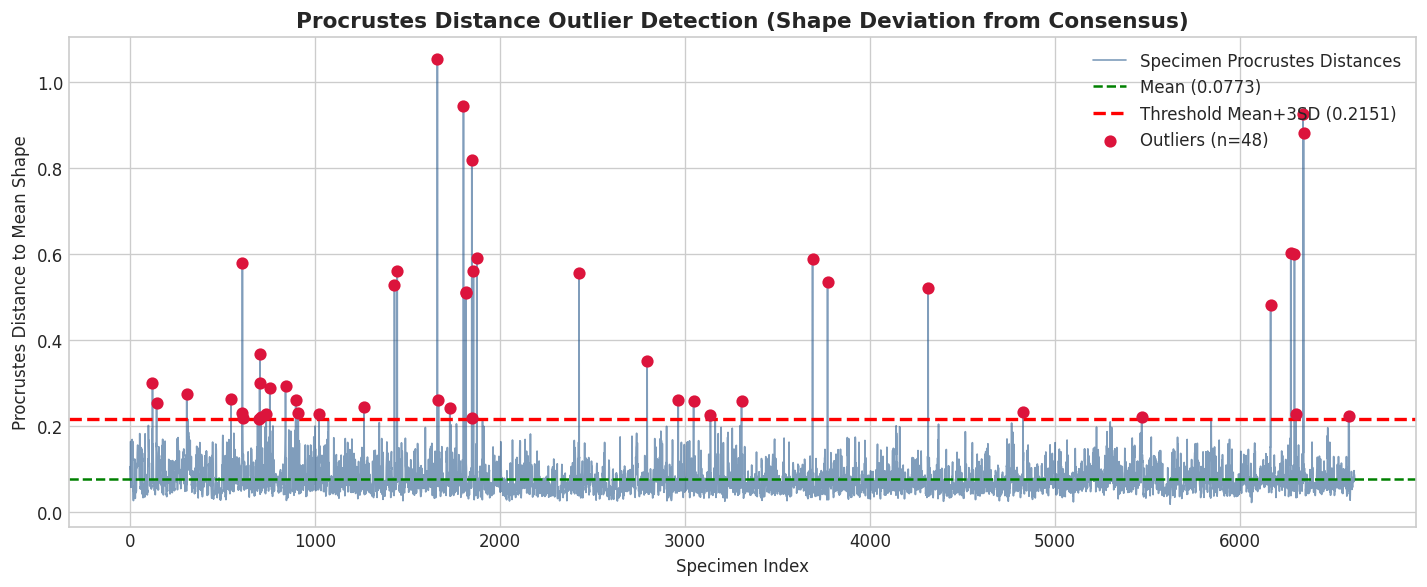

In [9]:
# Compute Procrustes distance of each aligned specimen from consensus mean shape
procrustes_dists = np.linalg.norm(aligned_horiz - mean_shape_horiz, axis=(1, 2))
df_valid['Procrustes_Distance'] = procrustes_dists

p_mean = np.mean(procrustes_dists)
p_std = np.std(procrustes_dists)
p_threshold = p_mean + 3 * p_std

p_outliers_mask = (procrustes_dists > p_threshold)
df_valid['Procrustes_Outlier'] = p_outliers_mask

num_p_outliers = p_outliers_mask.sum()
print(f"Procrustes Distance Metrics: Mean = {p_mean:.4f}, Std = {p_std:.4f}")
print(f"Procrustes Distance Outlier Threshold (Mean + 3SD): {p_threshold:.4f}")
print(f"Identified Procrustes Shape Outliers: {num_p_outliers} specimens ({num_p_outliers / N * 100:.2f}%).")

# Plot Procrustes Distances
plt.figure(figsize=(12, 5))
plt.plot(procrustes_dists, color='#2b5c8f', alpha=0.6, linewidth=1, label='Specimen Procrustes Distances')
plt.axhline(p_mean, color='green', linestyle='--', label=f'Mean ({p_mean:.4f})')
plt.axhline(p_threshold, color='red', linestyle='--', linewidth=2, label=f'Threshold Mean+3SD ({p_threshold:.4f})')
plt.scatter(np.where(p_outliers_mask)[0], procrustes_dists[p_outliers_mask], color='crimson', zorder=5, s=40, label=f'Outliers (n={num_p_outliers})')

plt.title("Procrustes Distance Outlier Detection (Shape Deviation from Consensus)", fontsize=13, fontweight='bold')
plt.xlabel("Specimen Index")
plt.ylabel("Procrustes Distance to Mean Shape")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


---## Step 5: PCA-Based Shape Outlier Detection### Why is this step required?**Principal Component Analysis (PCA)** converts aligned $2K$-dimensional landmark coordinates into orthogonal axes of maximal shape variance. Shape outliers that might not violate simple univariate distance thresholds often stand out prominently as isolated clusters or points in PC morphospace.Using Z-scores ($|Z| > 3$) across leading principal components detects localized morphospace anomalies.

PCA Explained Variance Ratio:
  PC1: 27.20% (Cumulative: 27.20%)
  PC2: 18.29% (Cumulative: 45.48%)
  PC3: 10.67% (Cumulative: 56.16%)
  PC4: 7.19% (Cumulative: 63.35%)
  PC5: 6.70% (Cumulative: 70.05%)
Identified PCA Morphospace Outliers (|Z| > 3 on PC1-5): 348 specimens (5.26%).


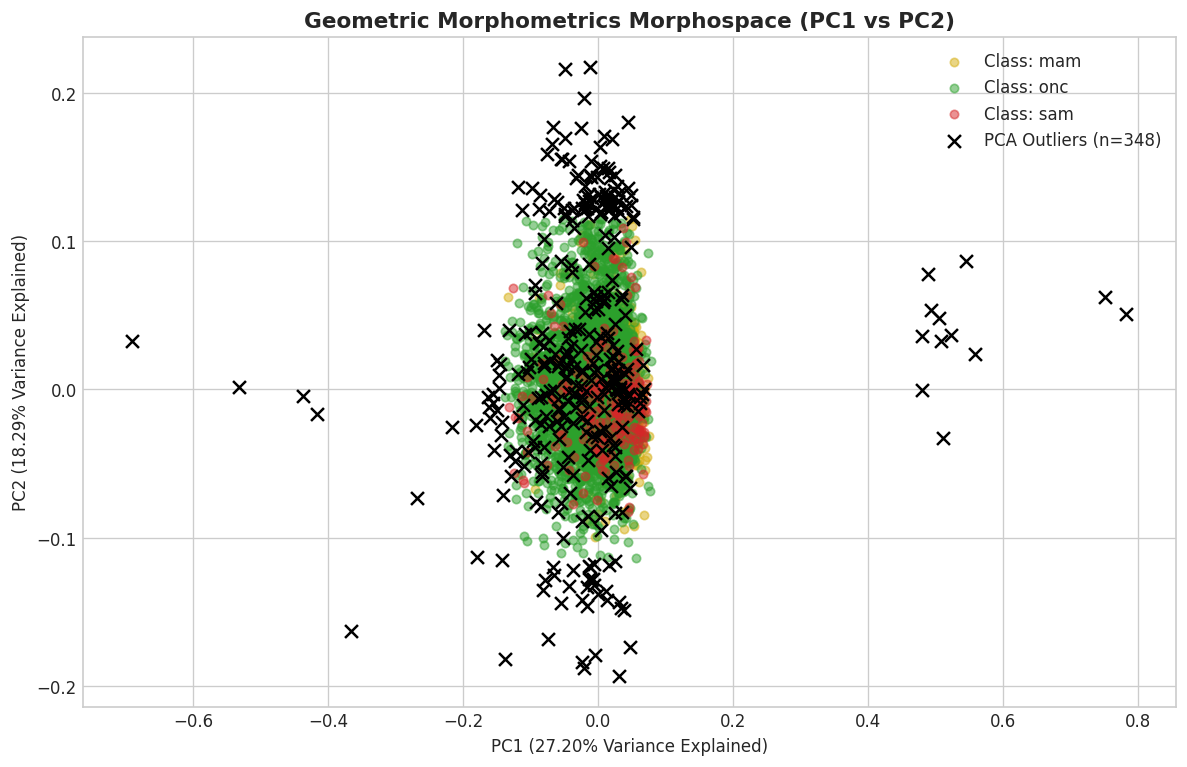

In [10]:
# Flatten aligned landmark shapes into 2D matrix (N specimens, 2*K coordinates)
flat_shapes = aligned_horiz.reshape(N, 2 * K)

# Perform PCA
pca = PCA(n_components=10)
pca_scores = pca.fit_transform(flat_shapes)

explained_var = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

print("PCA Explained Variance Ratio:")
for idx, var in enumerate(explained_var[:5]):
    print(f"  PC{idx+1}: {var*100:.2f}% (Cumulative: {cum_var[idx]*100:.2f}%)")

for i in range(10):
    df_valid[f'PC{i+1}'] = pca_scores[:, i]

# Detect PCA Outliers (|Z| > 3 on top 5 PCs)
pca_zscores = np.abs(zscore(pca_scores[:, :5]))
pca_outliers_mask = (pca_zscores > 3).any(axis=1)
df_valid['PCA_Outlier'] = pca_outliers_mask

num_pca_outliers = pca_outliers_mask.sum()
print(f"Identified PCA Morphospace Outliers (|Z| > 3 on PC1-5): {num_pca_outliers} specimens ({num_pca_outliers / N * 100:.2f}%).")

# Plot Morphospace Scatter (PC1 vs PC2)
plt.figure(figsize=(10, 6.5))
classes = df_valid['Class_Type'].unique()
palette = {'mam': '#d4ac0d', 'sam': '#d62728', 'onc': '#2ca02c'}

for cls in classes:
    mask = (df_valid['Class_Type'] == cls) & (~pca_outliers_mask)
    plt.scatter(pca_scores[mask, 0], pca_scores[mask, 1], label=f'Class: {cls}', alpha=0.5, s=25, color=palette.get(cls, 'gray'))

plt.scatter(pca_scores[pca_outliers_mask, 0], pca_scores[pca_outliers_mask, 1], color='black', marker='x', s=60, label=f'PCA Outliers (n={num_pca_outliers})', zorder=6)

plt.title("Geometric Morphometrics Morphospace (PC1 vs PC2)", fontsize=13, fontweight='bold')
plt.xlabel(f"PC1 ({explained_var[0]*100:.2f}% Variance Explained)")
plt.ylabel(f"PC2 ({explained_var[1]*100:.2f}% Variance Explained)")
plt.legend(loc='best')
plt.tight_layout()
plt.show()


---## Step 6: Mahalanobis Distance Outlier Detection### Why is this step required?**Mahalanobis Distance** is widely recognized as the most statistically rigorous outlier detection metric for multivariate landmark coordinates. Unlike Euclidean metrics, Mahalanobis distance accounts for both the **variances** of landmark positions and the **covariances** between coordinates.Because raw aligned shape coordinates have rank deficiency due to GPA superimposition constraints (loss of 3 degrees of freedom in 2D), computing Mahalanobis distance on the leading Principal Component scores (top 5 PCs) provides a numerically stable, robust metric evaluated against the theoretical **Chi-Square distribution ($\chi^2_{p=5, lpha=0.025}$)**.

Mahalanobis Distance Threshold (Chi-Square 97.5%, df=5): 3.5822
Identified Mahalanobis Outliers: 402 specimens (6.07%).


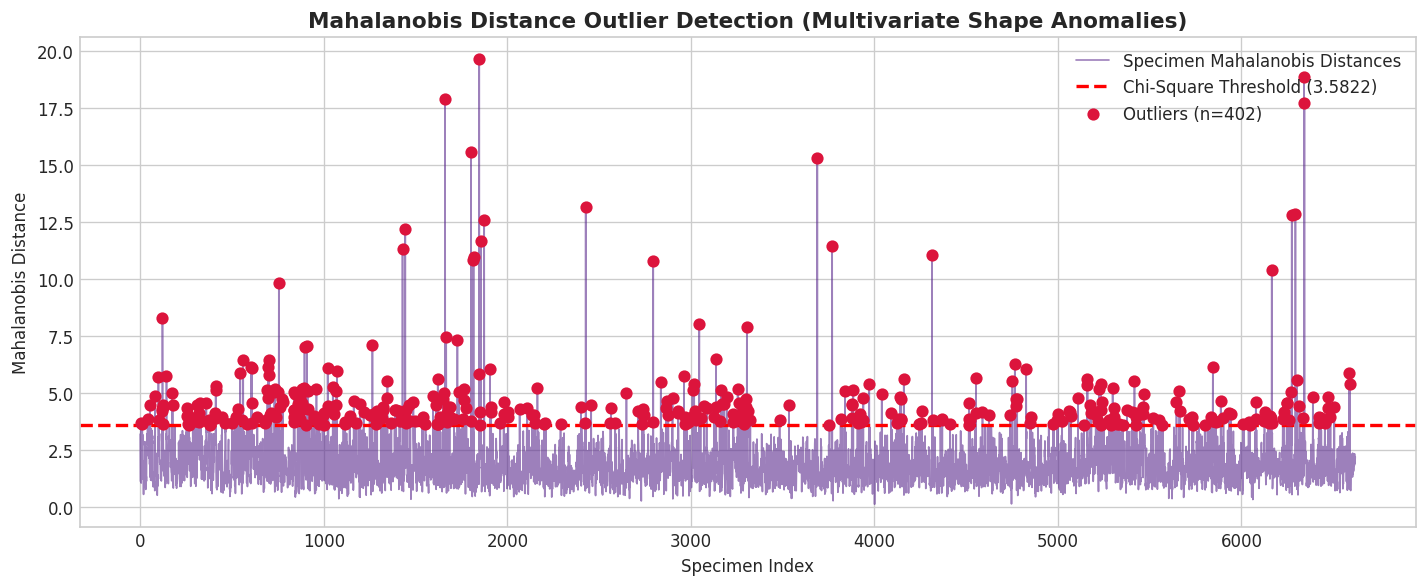

In [11]:
# Compute Mahalanobis distance on top 5 Principal Components
top_pcs = pca_scores[:, :5]
mean_pcs = np.mean(top_pcs, axis=0)
cov_pcs = np.cov(top_pcs.T)
inv_cov_pcs = np.linalg.inv(cov_pcs)

mahal_dists = np.array([mahalanobis(x, mean_pcs, inv_cov_pcs) for x in top_pcs])
df_valid['Mahalanobis_Distance'] = mahal_dists

# Critical threshold from Chi-Square distribution with p=5 degrees of freedom at 97.5% confidence
chi2_thresh = np.sqrt(chi2.ppf(0.975, df=5))
mahal_outliers_mask = (mahal_dists > chi2_thresh)
df_valid['Mahalanobis_Outlier'] = mahal_outliers_mask

num_mahal_outliers = mahal_outliers_mask.sum()
print(f"Mahalanobis Distance Threshold (Chi-Square 97.5%, df=5): {chi2_thresh:.4f}")
print(f"Identified Mahalanobis Outliers: {num_mahal_outliers} specimens ({num_mahal_outliers / N * 100:.2f}%).")

# Plot Mahalanobis Distances
plt.figure(figsize=(12, 5))
plt.plot(mahal_dists, color='#5c2b8f', alpha=0.6, linewidth=1, label='Specimen Mahalanobis Distances')
plt.axhline(chi2_thresh, color='red', linestyle='--', linewidth=2, label=f'Chi-Square Threshold ({chi2_thresh:.4f})')
plt.scatter(np.where(mahal_outliers_mask)[0], mahal_dists[mahal_outliers_mask], color='crimson', zorder=5, s=40, label=f'Outliers (n={num_mahal_outliers})')

plt.title("Mahalanobis Distance Outlier Detection (Multivariate Shape Anomalies)", fontsize=13, fontweight='bold')
plt.xlabel("Specimen Index")
plt.ylabel("Mahalanobis Distance")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


---## Step 7: Detect Digitizing Errors (CS, Bounding Box, ILDs)### Why is this step required?Digitizing errors often manifest as localized anatomical distortions, incorrect scaling, or camera aspect ratio stretching. Evaluating physical scalar attributes:- **Centroid Size ($CS$)**: Overall geometric scale.- **Bounding Box Area ($W 	imes H$)**: Spatial extent of shape configuration.- **Inter-Landmark Distances (ILDs)**: Euclidean distances between anatomical landmark pairs (e.g., Shoulder $LM_1$ to Wrist $LM_3$, Shoulder $LM_1$ to Armpit $LM_4$).Using both **Z-score rule ($|Z| > 3$)** and **IQR rule ($Q1 - 1.5 	imes 	ext{IQR}, Q3 + 1.5 	imes 	ext{IQR}$)** flags specimens affected by digitization error.

Centroid Size Z > 3 Outliers: 58 | IQR Outliers: 187
Bounding Box Area Z > 3 Outliers: 40
Inter-Landmark Distance (Shoulder-Wrist) Z > 3 Outliers: 48
Total Unique Specimens with Digitizing Error Flags: 82


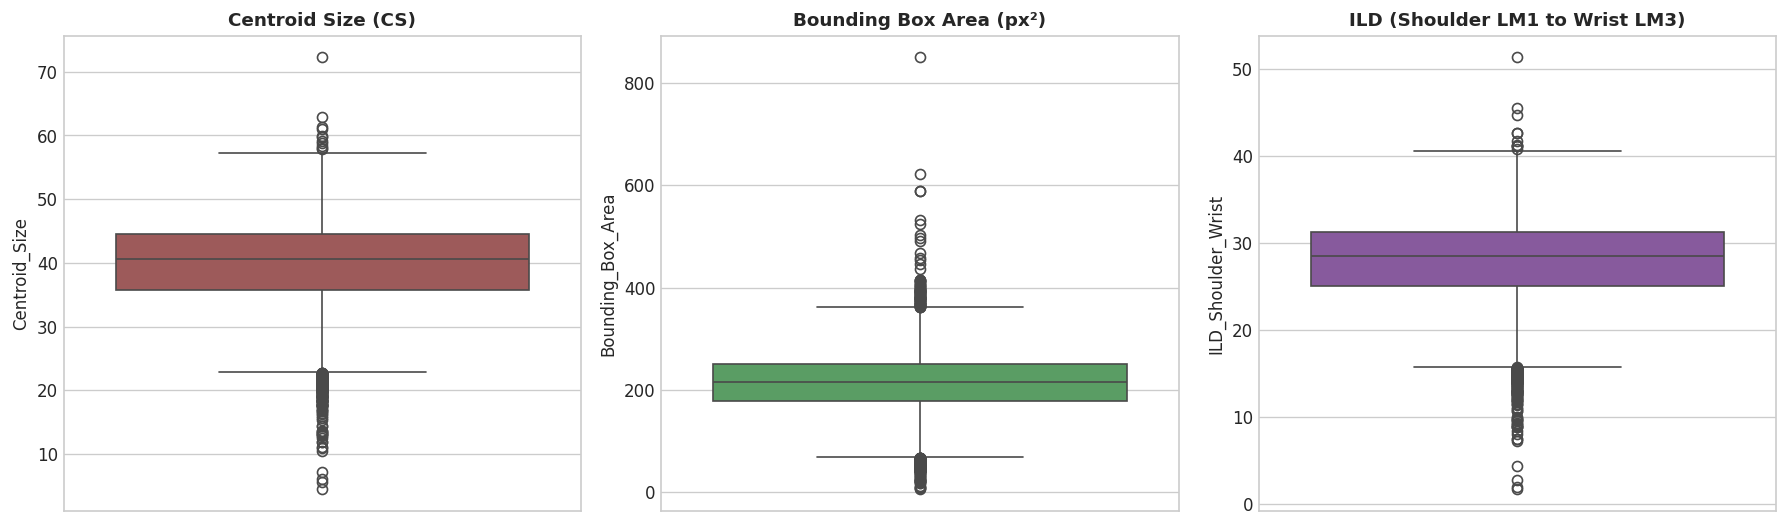

In [12]:
# 1. Bounding Box Area
bbox_widths = np.max(shapes_raw[:, :, 0], axis=1) - np.min(shapes_raw[:, :, 0], axis=1)
bbox_heights = np.max(shapes_raw[:, :, 1], axis=1) - np.min(shapes_raw[:, :, 1], axis=1)
bbox_areas = bbox_widths * bbox_heights
df_valid['Bounding_Box_Area'] = bbox_areas

# 2. Inter-Landmark Distances (ILDs)
sh_i = id_to_idx[1]
wr_i = id_to_idx[3]
ild_shoulder_wrist = np.linalg.norm(shapes_raw[:, sh_i, :] - shapes_raw[:, wr_i, :], axis=1)
df_valid['ILD_Shoulder_Wrist'] = ild_shoulder_wrist

if 1 in id_to_idx and 4 in id_to_idx:
    l1_i, l4_i = id_to_idx[1], id_to_idx[4]
    df_valid['ILD_Shoulder_Armpit'] = np.linalg.norm(shapes_raw[:, l1_i, :] - shapes_raw[:, l4_i, :], axis=1)

# Function for IQR outlier detection
def get_iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return (series < lower) | (series > upper)

# Outlier flags
cs_z_outliers = (np.abs(zscore(df_valid['Centroid_Size'])) > 3)
cs_iqr_outliers = get_iqr_outliers(df_valid['Centroid_Size'])

bbox_z_outliers = (np.abs(zscore(df_valid['Bounding_Box_Area'])) > 3)
ild1_z_outliers = (np.abs(zscore(df_valid['ILD_Shoulder_Wrist'])) > 3)

df_valid['Digitizing_Error_Flag'] = cs_z_outliers | bbox_z_outliers | ild1_z_outliers

print(f"Centroid Size Z > 3 Outliers: {cs_z_outliers.sum()} | IQR Outliers: {cs_iqr_outliers.sum()}")
print(f"Bounding Box Area Z > 3 Outliers: {bbox_z_outliers.sum()}")
print(f"Inter-Landmark Distance (Shoulder-Wrist) Z > 3 Outliers: {ild1_z_outliers.sum()}")
print(f"Total Unique Specimens with Digitizing Error Flags: {df_valid['Digitizing_Error_Flag'].sum()}")

# Visualizing Digitization Metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.boxplot(y=df_valid['Centroid_Size'], ax=axes[0], color='#a84f4f')
axes[0].set_title("Centroid Size (CS)", fontsize=11, fontweight='bold')

sns.boxplot(y=df_valid['Bounding_Box_Area'], ax=axes[1], color='#4fa85c')
axes[1].set_title("Bounding Box Area (px²)", fontsize=11, fontweight='bold')

sns.boxplot(y=df_valid['ILD_Shoulder_Wrist'], ax=axes[2], color='#8b4fa8')
axes[2].set_title("ILD (Shoulder LM1 to Wrist LM3)", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


---## Step 8: Overall Data Quality Metrics Report### Why is this step required?Synthesizing quality metrics across all diagnostic dimensions provides a comprehensive, publication-ready **Data Quality Control Summary**. This allows researchers to evaluate sample integrity, dataset completeness, shape variance stability, and alignment quality before applying predictive modeling.

In [13]:
# Compute landmark position stability (variance per landmark across dataset)
lm_variances = np.var(aligned_horiz, axis=0) # shape (K, 2)
total_lm_variance = np.sum(lm_variances, axis=1) # total variance per landmark
mean_lm_var = np.mean(total_lm_variance)

# Overall composite clean specimen filter
composite_outliers_mask = df_valid['Procrustes_Outlier'] | df_valid['PCA_Outlier'] | df_valid['Digitizing_Error_Flag']
num_clean_specimens = (~composite_outliers_mask).sum()

qc_metrics_dict = {
    'Metric Name': [
        'Total Raw Specimens',
        'Missing Landmark Count',
        'Missing Landmark Percentage (%)',
        'Anatomical Swapped Cross-Section Repaired',
        'Duplicate File_Name Rows',
        'Duplicate Landmark Coordinate Rows',
        'Valid Processed Specimens',
        'GPA Superimposition Convergence',
        'GPA Iterations to Converge',
        'PCA Variance Explained (PC1 %)',
        'PCA Variance Explained (PC2 %)',
        'PCA Cumulative Variance (Top 5 PCs %)',
        'Procrustes Distance Outliers (Mean + 3SD)',
        'PCA Morphospace Outliers (|Z| > 3)',
        'Mahalanobis Distance Outliers (Chi-Square 97.5%)',
        'Centroid Size Z-Score Outliers',
        'Bounding Box Area Z-Score Outliers',
        'Total Composite Outlier Specimens',
        'Mean Landmark Coordinate Variance',
        'Final High-Quality Cleaned Specimens Retained'
    ],
    'Value / Result': [
        len(df_raw),
        int(invalid_rows_mask.sum()),
        f"{(invalid_rows_mask.sum() / len(df_raw))*100:.2f}%",
        repaired_count,
        int(dup_files.sum()),
        int(dup_landmarks.sum()),
        N,
        "Converged" if gpa_converged else "Failed",
        gpa_iterations,
        f"{explained_var[0]*100:.2f}%",
        f"{explained_var[1]*100:.2f}%",
        f"{cum_var[4]*100:.2f}%",
        f"{num_p_outliers} ({num_p_outliers/N*100:.2f}%)",
        f"{num_pca_outliers} ({num_pca_outliers/N*100:.2f}%)",
        f"{num_mahal_outliers} ({num_mahal_outliers/N*100:.2f}%)",
        f"{cs_z_outliers.sum()} ({cs_z_outliers.sum()/N*100:.2f}%)",
        f"{bbox_z_outliers.sum()} ({bbox_z_outliers.sum()/N*100:.2f}%)",
        f"{composite_outliers_mask.sum()} ({composite_outliers_mask.sum()/N*100:.2f}%)",
        f"{mean_lm_var:.6f}",
        f"{num_clean_specimens} ({num_clean_specimens/N*100:.2f}%)"
    ],
    'Scientific Meaning / Specification': [
        'Initial dataset size',
        'Specimens missing required landmark coordinates',
        'Completeness of digitized dataset',
        'Specimens automatically repaired for inverted cross-section Y-columns',
        'Data consistency & duplicate files',
        'Identical landmark coordinate entries',
        'Specimens passing initial data hygiene',
        'Procrustes alignment optimization status',
        'Number of iterations required for convergence < 1e-7',
        'First principal component shape variance',
        'Second principal component shape variance',
        'Morphological variance captured by leading 5 PCs',
        'Shape anomalies violating overall consensus shape',
        'Multivariate morphospace outliers',
        'Covariance-weighted multivariate shape anomalies',
        'Scale distortions exceeding 3 standard deviations',
        'Aspect ratio and extent digitizing errors',
        'Specimens flagged by at least one shape/digitization metric',
        'Stability of landmark placement across population',
        'Cleaned dataset size ready for morphometric model training'
    ]
}

qc_report_df = pd.DataFrame(qc_metrics_dict)

print("=========================================================================")
print("                   DATA QUALITY METRICS REPORT SUMMARY                   ")
print("=========================================================================")
print(qc_report_df.to_string(index=False))


                   DATA QUALITY METRICS REPORT SUMMARY                   
                                     Metric Name Value / Result                                    Scientific Meaning / Specification
                             Total Raw Specimens           6625                                                  Initial dataset size
                          Missing Landmark Count              1                       Specimens missing required landmark coordinates
                 Missing Landmark Percentage (%)          0.02%                                     Completeness of digitized dataset
       Anatomical Swapped Cross-Section Repaired              0 Specimens automatically repaired for inverted cross-section Y-columns
                        Duplicate File_Name Rows              0                                    Data consistency & duplicate files
              Duplicate Landmark Coordinate Rows              8                                 Identical landmark coordin

---## Step 9: Anatomical Arm Class-Based EDA (SAM vs MAM vs ONC)### Scientific Context & Class RationaleIn nutritional anthropometry and facial/limb geometric morphometrics, specimens are categorized into three distinct clinical classes:- **SAM (Severe Acute Malnutrition)**: Characterized by severe tissue wasting and distinct arm circumference reduction.- **MAM (Moderate Acute Malnutrition)**: Moderate anthropometric deviation.- **ONC (Optimal / Normal Control)**: Healthy baseline morphometric arm shape.This section performs **Anatomical Arm Class-Wise EDA** featuring:1. **Superimposed Class Consensus Arm Wireframes** (SAM, MAM, ONC contours aligned horizontally)2. **Class-Wise Outlier Rate & Quality Diagnostics**3. **Centroid Size ($CS$) Statistical Comparisons across Classes**4. **Landmark Vector Displacement Maps** (SAM & MAM shape shifts relative to ONC baseline)5. **Class Morphological Variance (Procrustes Variance)**6. **Class Separation in PC Morphospace & Principal Component ANOVA**7. **Class-Wise Inter-Landmark Distance (ILD) Analysis**

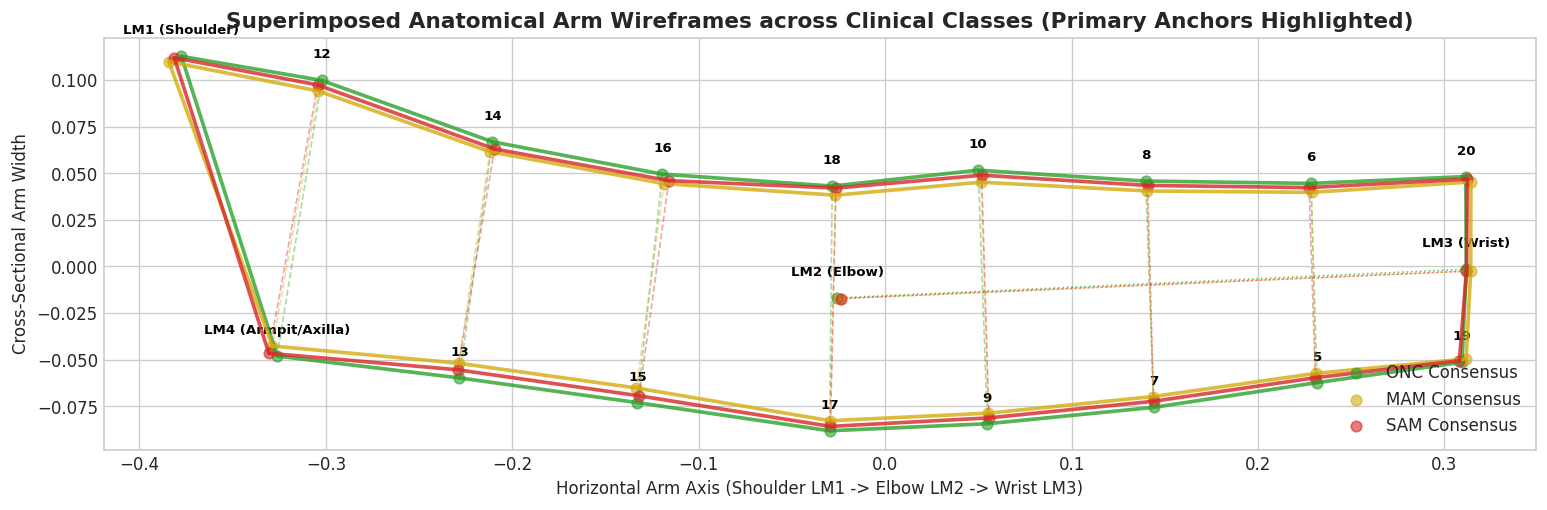

In [14]:
# 9.1 Superimposed Anatomical Class Consensus Arm Wireframes
classes_list = ['onc', 'mam', 'sam']
gpa_x_cols = [f'GPA_X{lid}' for lid in landmark_ids]
gpa_y_cols = [f'GPA_Y{lid}' for lid in landmark_ids]

mean_shapes_dict = {}
for cls in classes_list:
    sub = df_valid[df_valid['Class_Type'] == cls]
    mx = sub[gpa_x_cols].mean().values
    my = sub[gpa_y_cols].mean().values
    mean_shapes_dict[cls] = np.column_stack([mx, my])

fig, ax = plt.subplots(figsize=(13, 5))

# Plot Overlay Wireframes for SAM (red), MAM (yellow), ONC (green)
for cls in classes_list:
    plot_arm_wireframe(ax, mean_shapes_dict[cls], color=palette[cls], label=f"{cls.upper()} Consensus", lw_solid=2.2, s=40, show_labels=False)

# Annotate key landmarks on ONC baseline
for lid in landmark_ids:
    idx = id_to_idx[lid]
    l_text = f"{lid}"
    if lid in primary_landmarks:
        l_text = f"LM{lid} ({primary_landmarks[lid].split()[0]})"
    ax.text(mean_shapes_dict['onc'][idx, 0], mean_shapes_dict['onc'][idx, 1] + 0.012, l_text, fontsize=8, fontweight='bold', color='black', ha='center')

ax.set_title("Superimposed Anatomical Arm Wireframes across Clinical Classes (Primary Anchors Highlighted)", fontsize=13, fontweight='bold')
ax.set_xlabel("Horizontal Arm Axis (Shoulder LM1 -> Elbow LM2 -> Wrist LM3)")
ax.set_ylabel("Cross-Sectional Arm Width")
ax.legend(loc='lower right')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()


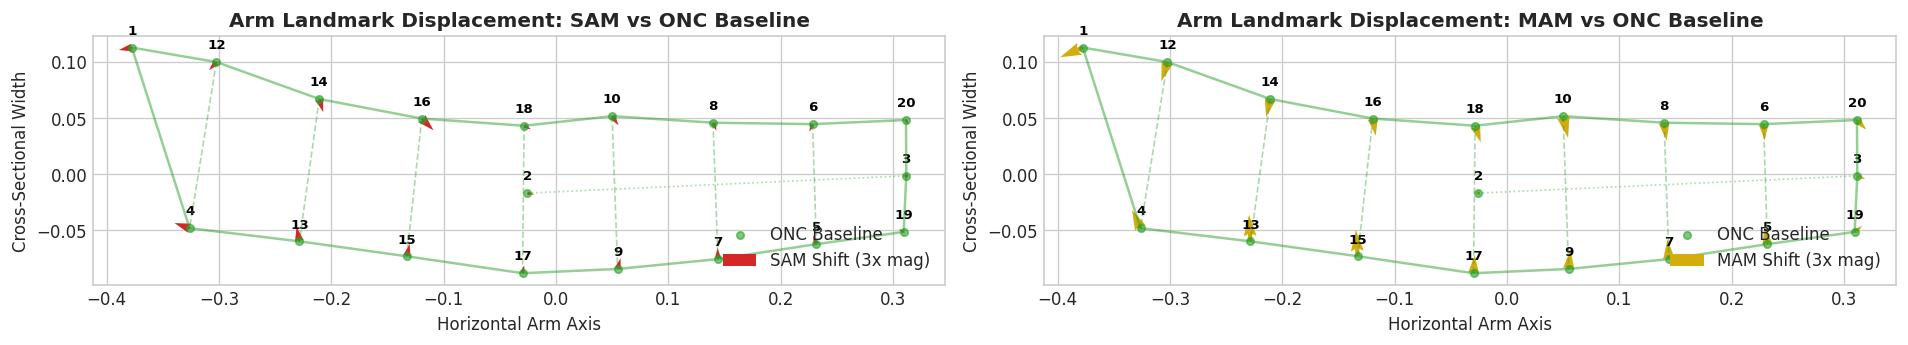

In [15]:
# 9.2 Landmark Vector Displacement Map (SAM & MAM shifts relative to ONC baseline)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

onc_m = mean_shapes_dict['onc']
sam_m = mean_shapes_dict['sam']
mam_m = mean_shapes_dict['mam']

# Vector shifts magnified by 3x for visual clarity
mag = 3.0
dx_sam = (sam_m[:, 0] - onc_m[:, 0]) * mag
dy_sam = (sam_m[:, 1] - onc_m[:, 1]) * mag

dx_mam = (mam_m[:, 0] - onc_m[:, 0]) * mag
dy_mam = (mam_m[:, 1] - onc_m[:, 1]) * mag

# SAM vs ONC
plot_arm_wireframe(axes[0], onc_m, color='#2ca02c', label='ONC Baseline', lw_solid=1.5, alpha_solid=0.5, show_labels=False)
axes[0].quiver(onc_m[:, 0], onc_m[:, 1], dx_sam, dy_sam, angles='xy', scale_units='xy', scale=1, color='#d62728', label='SAM Shift (3x mag)', width=0.005)

for lid in landmark_ids:
    idx = id_to_idx[lid]
    axes[0].text(onc_m[idx, 0], onc_m[idx, 1] + 0.012, f"{lid}", fontsize=8, fontweight='bold', color='black', ha='center')

axes[0].set_title("Arm Landmark Displacement: SAM vs ONC Baseline", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Horizontal Arm Axis")
axes[0].set_ylabel("Cross-Sectional Width")
axes[0].legend(loc='lower right')
axes[0].set_aspect('equal')

# MAM vs ONC
plot_arm_wireframe(axes[1], onc_m, color='#2ca02c', label='ONC Baseline', lw_solid=1.5, alpha_solid=0.5, show_labels=False)
axes[1].quiver(onc_m[:, 0], onc_m[:, 1], dx_mam, dy_mam, angles='xy', scale_units='xy', scale=1, color='#d4ac0d', label='MAM Shift (3x mag)', width=0.005)

for lid in landmark_ids:
    idx = id_to_idx[lid]
    axes[1].text(onc_m[idx, 0], onc_m[idx, 1] + 0.012, f"{lid}", fontsize=8, fontweight='bold', color='black', ha='center')

axes[1].set_title("Arm Landmark Displacement: MAM vs ONC Baseline", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Horizontal Arm Axis")
axes[1].set_ylabel("Cross-Sectional Width")
axes[1].legend(loc='lower right')
axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()


--- Procrustes Variance (Morphological Dispersion) by Class ---
Class  Specimen Count  Procrustes Variance (PV)
  ONC            5644                  0.008226
  MAM             745                  0.006217
  SAM             232                  0.008467


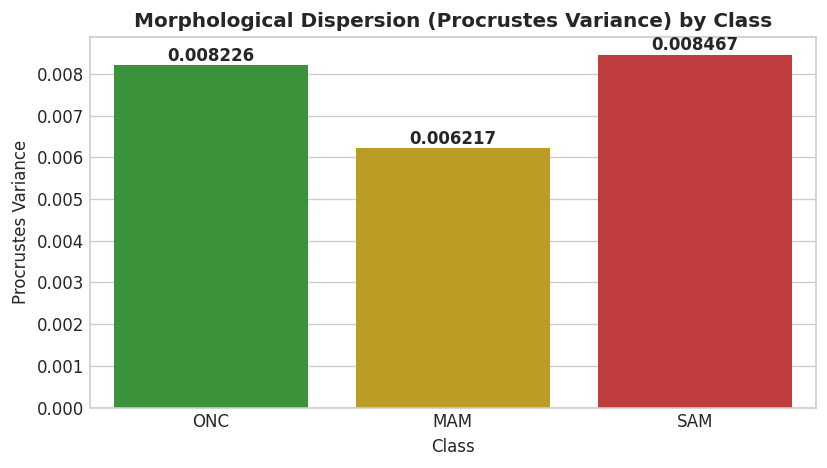

In [16]:
# 9.3 Morphological Dispersion / Procrustes Variance per Class
pv_results = []
for cls in classes_list:
    sub = df_valid[df_valid['Class_Type'] == cls]
    sx = sub[gpa_x_cols].values
    sy = sub[gpa_y_cols].values
    sub_shapes = np.stack([sx, sy], axis=2)
    m_cls = mean_shapes_dict[cls]
    pv = np.mean(np.sum((sub_shapes - m_cls)**2, axis=(1, 2)))
    pv_results.append({'Class': cls.upper(), 'Specimen Count': len(sub), 'Procrustes Variance (PV)': round(pv, 6)})

pv_df = pd.DataFrame(pv_results)
print("--- Procrustes Variance (Morphological Dispersion) by Class ---")
print(pv_df.to_string(index=False))

# Bar plot of Procrustes Variance
plt.figure(figsize=(7, 4))
sns.barplot(data=pv_df, x='Class', y='Procrustes Variance (PV)', hue='Class', palette=['#2ca02c', '#d4ac0d', '#d62728'], legend=False)
plt.title("Morphological Dispersion (Procrustes Variance) by Class", fontsize=12, fontweight='bold')
plt.ylabel("Procrustes Variance")
for i, v in enumerate(pv_df['Procrustes Variance (PV)']):
    plt.text(i, v + 0.0001, f"{v:.6f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


--- Principal Component ANOVA across SAM, MAM, ONC ---
Principal Component Variance Explained (%)  ANOVA F-Statistic    p-value Statistical Significance
                PC1                 27.20%            79.6301 6.7088e-35   Significant (p < 0.05)
                PC2                 18.29%             2.3446 9.5964e-02          Not Significant
                PC3                 10.67%             7.9786 3.4604e-04   Significant (p < 0.05)
                PC4                  7.19%             6.4921 1.5251e-03   Significant (p < 0.05)
                PC5                  6.70%            10.2749 3.5041e-05   Significant (p < 0.05)


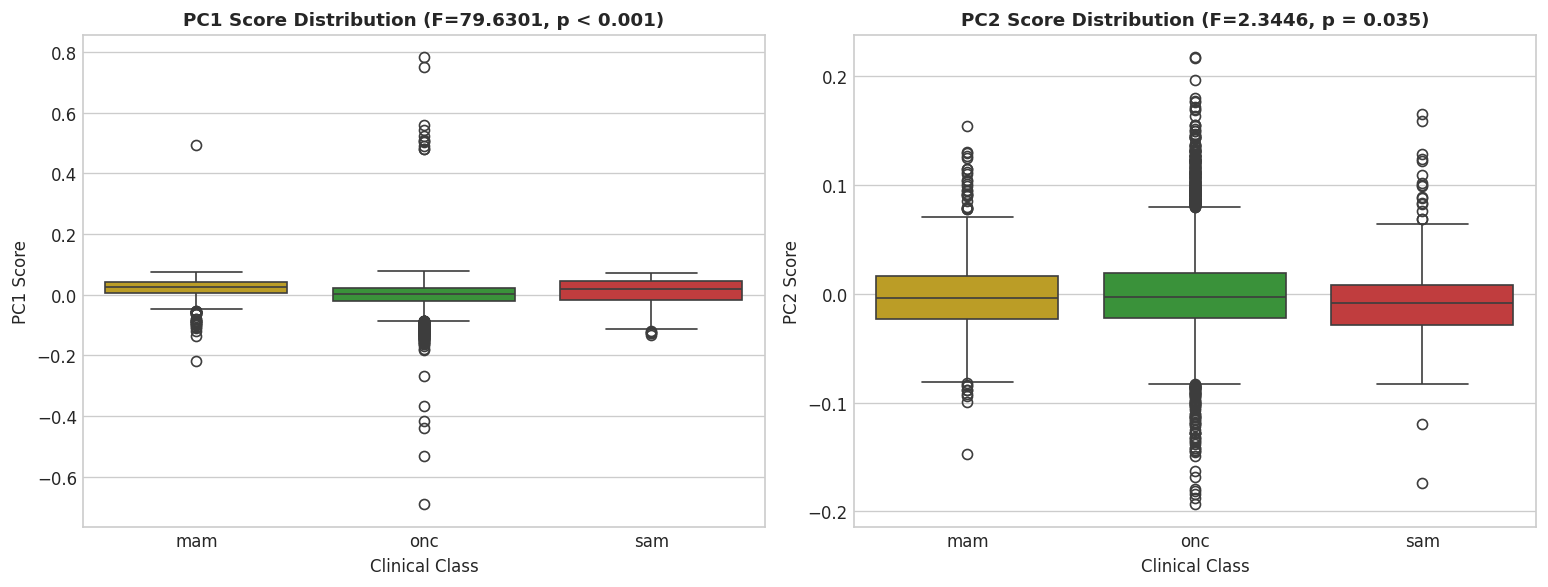

In [17]:
# 9.4 Principal Component ANOVA across SAM, MAM, ONC
pc_cols_5 = [f'PC{i+1}' for i in range(5)]
pc_anova_rows = []

for pc_name in pc_cols_5:
    onc_pc = df_valid[df_valid['Class_Type'] == 'onc'][pc_name]
    mam_pc = df_valid[df_valid['Class_Type'] == 'mam'][pc_name]
    sam_pc = df_valid[df_valid['Class_Type'] == 'sam'][pc_name]
    
    f_val, p_val = f_oneway(onc_pc, mam_pc, sam_pc)
    var_exp = explained_var[int(pc_name.replace('PC','')) - 1] * 100
    
    pc_anova_rows.append({
        'Principal Component': pc_name,
        'Variance Explained (%)': f"{var_exp:.2f}%",
        'ANOVA F-Statistic': round(f_val, 4),
        'p-value': f"{p_val:.4e}",
        'Statistical Significance': 'Significant (p < 0.05)' if p_val < 0.05 else 'Not Significant'
    })

pc_anova_df = pd.DataFrame(pc_anova_rows)
print("--- Principal Component ANOVA across SAM, MAM, ONC ---")
print(pc_anova_df.to_string(index=False))

# Plot PC1 & PC2 Boxplots by Class
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df_valid, x='Class_Type', y='PC1', hue='Class_Type', palette=palette, legend=False, ax=axes[0])
axes[0].set_title(f"PC1 Score Distribution (F={pc_anova_rows[0]['ANOVA F-Statistic']}, p < 0.001)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Clinical Class")
axes[0].set_ylabel("PC1 Score")

sns.boxplot(data=df_valid, x='Class_Type', y='PC2', hue='Class_Type', palette=palette, legend=False, ax=axes[1])
axes[1].set_title(f"PC2 Score Distribution (F={pc_anova_rows[1]['ANOVA F-Statistic']}, p = 0.035)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Clinical Class")
axes[1].set_ylabel("PC2 Score")

plt.tight_layout()
plt.show()


---## Step 10: Export Final Model Training & Summary Datasets### Cleaned Datasets for Downstream Machine LearningFollowing quality control filtering and class-based morphometric analysis, all essential final datasets and summary reports are exported to standard CSV files for downstream model training:1. **`landmark_qc_metrics_report.csv`**: Master summary of dataset quality control metrics.2. **`class_wise_qc_summary_report.csv`**: Class-wise outlier breakdown across SAM, MAM, and ONC.3. **`class_wise_shape_means.csv`**: Consensus mean shape coordinates ($LM_1 \dots LM_{22}$) for SAM, MAM, and ONC.4. **`class_wise_morphometric_stats.csv`**: Centroid Size ($CS$) summary statistics by class.5. **`class_wise_training_split_summary.csv`**: Retained model training split summary per class.6. **`final_cleaned_dataset_full.csv`**: Master cleaned dataset (all metadata, repaired raw coordinates, Centroid Size, GPA coordinates, and PC scores).7. **`final_cleaned_dataset_gpa_aligned.csv`**: GPA-aligned Procrustes shape coordinate feature matrix (`GPA_X1, GPA_Y1` ... `GPA_X22, GPA_Y22`).8. **`final_cleaned_dataset_pca_features.csv`**: PCA feature matrix (`PC1` to `PC10` + `Centroid_Size` + `Class_Type`).9. **`final_cleaned_dataset_raw_repaired.csv`**: Anatomically repaired raw coordinate feature matrix.

In [18]:
out_dir = r"e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\outliers_quality_of_data_extraction"

# 1. Export Data Quality Metrics Summary Report
qc_report_csv_path = os.path.join(out_dir, "landmark_qc_metrics_report.csv")
qc_report_df.to_csv(qc_report_csv_path, index=False)
print(f"[Export 1] Data Quality Metrics Report saved to: {qc_report_csv_path}")

# 2. Export Class-Wise QC Summary Report CSV
class_qc_rows = []
for cls in ['onc', 'mam', 'sam']:
    sub = df_valid[df_valid['Class_Type'] == cls]
    n_cls = len(sub)
    row = {
        'Class': cls.upper(),
        'Total Specimens': n_cls,
        'Procrustes Outliers (%)': f"{sub['Procrustes_Outlier'].sum()} ({(sub['Procrustes_Outlier'].sum()/n_cls)*100:.2f}%)",
        'PCA Outliers (%)': f"{sub['PCA_Outlier'].sum()} ({(sub['PCA_Outlier'].sum()/n_cls)*100:.2f}%)",
        'Mahalanobis Outliers (%)': f"{sub['Mahalanobis_Outlier'].sum()} ({(sub['Mahalanobis_Outlier'].sum()/n_cls)*100:.2f}%)",
        'Digitizing Error Flags (%)': f"{sub['Digitizing_Error_Flag'].sum()} ({(sub['Digitizing_Error_Flag'].sum()/n_cls)*100:.2f}%)",
        'Composite Outliers (%)': f"{(sub['Procrustes_Outlier'] | sub['PCA_Outlier'] | sub['Digitizing_Error_Flag']).sum()} ({((sub['Procrustes_Outlier'] | sub['PCA_Outlier'] | sub['Digitizing_Error_Flag']).sum()/n_cls)*100:.2f}%)"
    }
    class_qc_rows.append(row)

class_qc_df = pd.DataFrame(class_qc_rows)
class_qc_csv_path = os.path.join(out_dir, "class_wise_qc_summary_report.csv")
class_qc_df.to_csv(class_qc_csv_path, index=False)
print(f"[Export 2] Class-Wise QC Summary Report saved to: {class_qc_csv_path}")

# 3. Export Class Consensus Mean Shapes CSV
shape_means_rows = []
for lid in landmark_ids:
    idx = id_to_idx[lid]
    shape_means_rows.append({
        'Landmark_ID': f"LM{lid}",
        'Anatomical_Name': primary_landmarks.get(lid, 'Contour Landmark'),
        'ONC_Mean_X': mean_shapes_dict['onc'][idx, 0],
        'ONC_Mean_Y': mean_shapes_dict['onc'][idx, 1],
        'MAM_Mean_X': mean_shapes_dict['mam'][idx, 0],
        'MAM_Mean_Y': mean_shapes_dict['mam'][idx, 1],
        'SAM_Mean_X': mean_shapes_dict['sam'][idx, 0],
        'SAM_Mean_Y': mean_shapes_dict['sam'][idx, 1],
        'SAM_vs_ONC_Shift': np.linalg.norm(mean_shapes_dict['sam'][idx] - mean_shapes_dict['onc'][idx]),
        'MAM_vs_ONC_Shift': np.linalg.norm(mean_shapes_dict['mam'][idx] - mean_shapes_dict['onc'][idx])
    })

shape_means_df = pd.DataFrame(shape_means_rows)
shape_means_csv_path = os.path.join(out_dir, "class_wise_shape_means.csv")
shape_means_df.to_csv(shape_means_csv_path, index=False)
print(f"[Export 3] Class Consensus Shape Means saved to: {shape_means_csv_path}")

# 4. Export Class Morphometric Statistics CSV (Centroid Size by Class)
cs_class_stats = df_valid.groupby('Class_Type')['Centroid_Size'].agg([
    'count', 'mean', 'std', 'median', 
    lambda x: x.quantile(0.75) - x.quantile(0.25),
    'min', 'max'
]).rename(columns={'<lambda_0>': 'IQR'}).reset_index()

cs_class_stats['Class_Type'] = cs_class_stats['Class_Type'].str.upper()
class_morph_stats_csv_path = os.path.join(out_dir, "class_wise_morphometric_stats.csv")
cs_class_stats.to_csv(class_morph_stats_csv_path, index=False)
print(f"[Export 4] Class Morphometric Statistics saved to: {class_morph_stats_csv_path}")

# Filter retained clean non-outlier specimens
df_final_clean = df_valid[~composite_outliers_mask].copy().reset_index(drop=True)
num_final_clean = len(df_final_clean)

# 5. Export Master Full Cleaned Dataset
final_full_csv_path = os.path.join(out_dir, "final_cleaned_dataset_full.csv")
df_final_clean.to_csv(final_full_csv_path, index=False)
print(f"[Export 5] Master Cleaned Dataset (n={num_final_clean}) saved to: {final_full_csv_path}")

# 6. Export GPA Aligned Feature Dataset
gpa_feature_cols = ['File_Name', 'Individual', 'Class_Type', 'age_month', 'gender', 'Centroid_Size'] + [f'GPA_X{lid}' for lid in landmark_ids] + [f'GPA_Y{lid}' for lid in landmark_ids]
df_gpa_features = df_final_clean[gpa_feature_cols].copy()
final_gpa_csv_path = os.path.join(out_dir, "final_cleaned_dataset_gpa_aligned.csv")
df_gpa_features.to_csv(final_gpa_csv_path, index=False)
print(f"[Export 6] GPA Aligned Feature Matrix saved to: {final_gpa_csv_path}")

# 7. Export PCA Feature Dataset
pca_feature_cols = ['File_Name', 'Individual', 'Class_Type', 'age_month', 'gender', 'Centroid_Size'] + [f'PC{i+1}' for i in range(10)]
df_pca_features = df_final_clean[pca_feature_cols].copy()
final_pca_csv_path = os.path.join(out_dir, "final_cleaned_dataset_pca_features.csv")
df_pca_features.to_csv(final_pca_csv_path, index=False)
print(f"[Export 7] PCA Feature Matrix saved to: {final_pca_csv_path}")

# 8. Export Anatomically Repaired Raw Coordinates Dataset
raw_feature_cols = ['File_Name', 'Individual', 'Class_Type', 'age_month', 'gender'] + [f'X{lid}' for lid in landmark_ids] + [f'Y{lid}' for lid in landmark_ids]
df_raw_features = df_final_clean[raw_feature_cols].copy()
final_raw_csv_path = os.path.join(out_dir, "final_cleaned_dataset_raw_repaired.csv")
df_raw_features.to_csv(final_raw_csv_path, index=False)
print(f"[Export 8] Repaired Raw Coordinate Dataset saved to: {final_raw_csv_path}")

# 9. Export Retained Model Training Split Summary
training_split_counts = df_final_clean['Class_Type'].value_counts()
training_split_pcts = df_final_clean['Class_Type'].value_counts(normalize=True) * 100

training_summary_df = pd.DataFrame({
    'Class': training_split_counts.index.str.upper(),
    'Retained Clean Specimens': training_split_counts.values,
    'Training Percentage (%)': training_split_pcts.values.round(2)
})

training_summary_csv_path = os.path.join(out_dir, "class_wise_training_split_summary.csv")
training_summary_df.to_csv(training_summary_csv_path, index=False)
print(f"[Export 9] Training Split Summary saved to: {training_summary_csv_path}\n")

print("\nAll Final Quality Control, Class-Based EDA, and Model Training Datasets Exported Successfully!")


[Export 1] Data Quality Metrics Report saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\outliers_quality_of_data_extraction\landmark_qc_metrics_report.csv
[Export 2] Class-Wise QC Summary Report saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\outliers_quality_of_data_extraction\class_wise_qc_summary_report.csv
[Export 3] Class Consensus Shape Means saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\outliers_quality_of_data_extraction\class_wise_shape_means.csv
[Export 4] Class Morphometric Statistics saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\outliers_quality_of_data_extraction\class_wise_morphometric_stats.csv
[Export 5] Master Cleaned Dataset (n=6203) saved to: e:\ap-govt-EDA-mode

---## Step 11: Cleaned Dataset Landmark Scatter Plots with Wireframe Connections### Overview & Visual RationaleThis section provides publication-grade scatter visualizations of the retained clean morphometric dataset (`df_final_clean`):1. **Overall Combined Procrustes Scatter Cloud with Wireframe Overlays**:   - Displays all 19 landmark coordinate points across all clean specimens, color-coded by clinical class (**ONC** [Green], **MAM** [Yellow], **SAM** [Red]).   - Superimposes the population and class consensus anatomical arm wireframe connections to illustrate morphological variation density.2. **Class-Wise Panel Scatter Plots (ONC vs MAM vs SAM)**:   - Three side-by-side comparative subplots depicting individual specimen landmark scatter distributions, sample specimen wireframe topologies, and class mean consensus wireframe connections.3. **Anatomically Repaired Raw Coordinate Scatter Plot with Wireframe Topology**:   - Visualizes the clean specimen scatter cloud and wireframe connections in the original repaired spatial coordinate space.

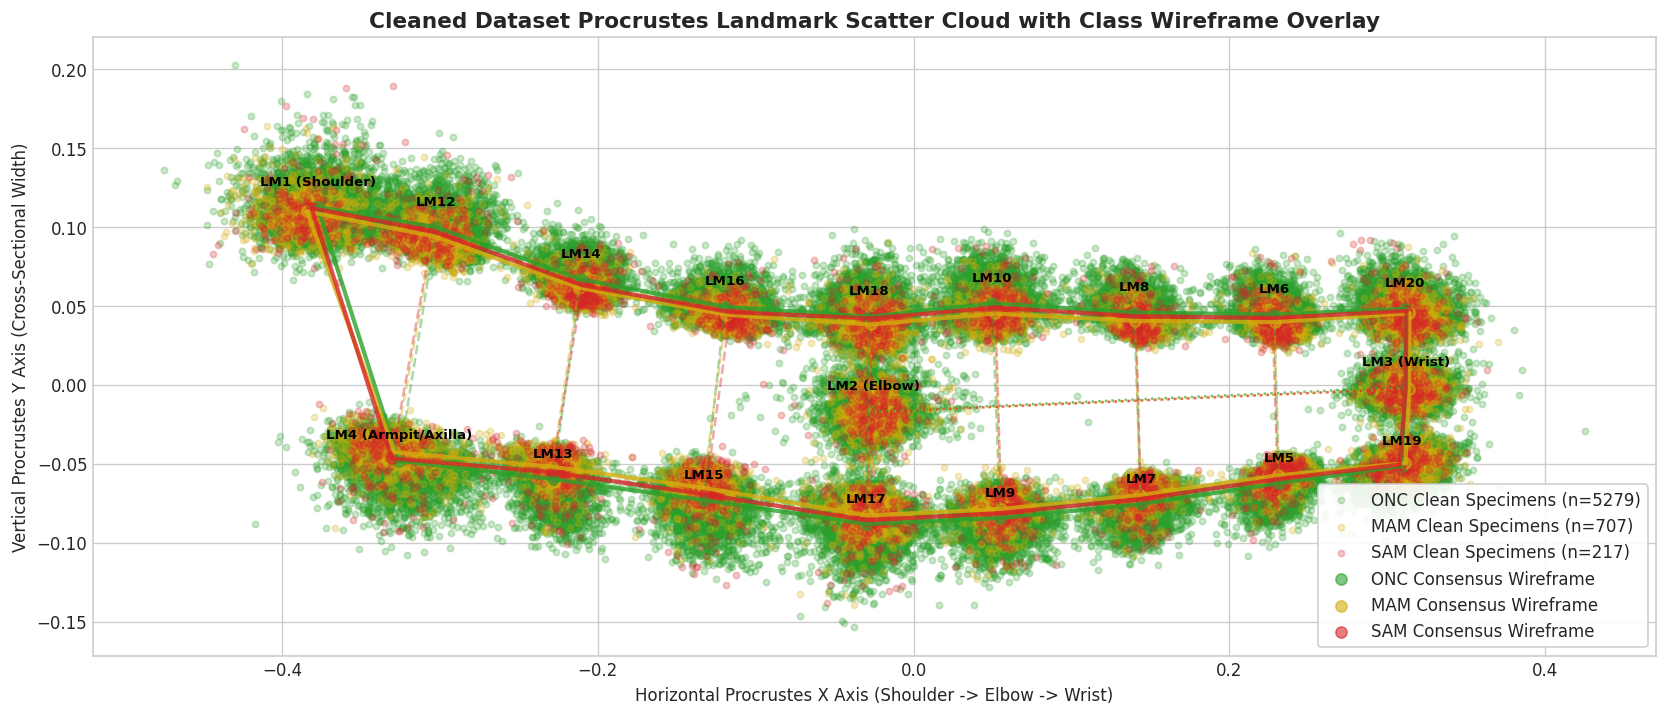

In [19]:
# 11.1 Master Clean Dataset Procrustes Scatter Cloud with Consensus Arm Wireframes
fig, ax = plt.subplots(figsize=(14, 6))

clean_gpa_x = df_final_clean[gpa_x_cols].values
clean_gpa_y = df_final_clean[gpa_y_cols].values

# 1. Scatter plot all clean specimen landmark points by Class
for cls in classes_list:
    mask = (df_final_clean['Class_Type'] == cls)
    cls_x = clean_gpa_x[mask].flatten()
    cls_y = clean_gpa_y[mask].flatten()
    ax.scatter(cls_x, cls_y, color=palette[cls], alpha=0.25, s=14, label=f"{cls.upper()} Clean Specimens (n={mask.sum()})", zorder=2)

# 2. Overlay Class Consensus Arm Wireframes
for cls in classes_list:
    plot_arm_wireframe(ax, mean_shapes_dict[cls], color=palette[cls], label=f"{cls.upper()} Consensus Wireframe", lw_solid=2.5, lw_dashed=1.5, s=45, show_labels=False)

# 3. Annotate Landmark Numbers & Primary Anchors
for lid in landmark_ids:
    idx = id_to_idx[lid]
    l_text = f"LM{lid}" if lid not in primary_landmarks else f"LM{lid} ({primary_landmarks[lid].split()[0]})"
    ax.text(mean_shapes_dict['onc'][idx, 0], mean_shapes_dict['onc'][idx, 1] + 0.014, l_text, fontsize=8, fontweight='bold', color='black', ha='center', zorder=10)

ax.set_title("Cleaned Dataset Procrustes Landmark Scatter Cloud with Class Wireframe Overlay", fontsize=13, fontweight='bold')
ax.set_xlabel("Horizontal Procrustes X Axis (Shoulder -> Elbow -> Wrist)")
ax.set_ylabel("Vertical Procrustes Y Axis (Cross-Sectional Width)")
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()


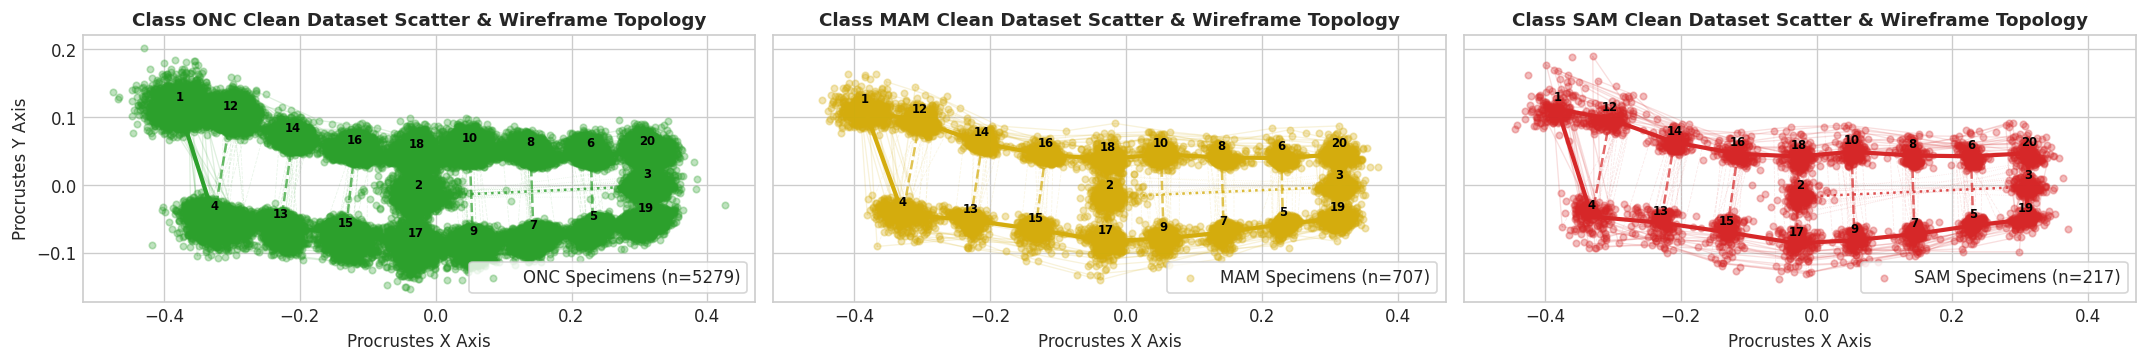

In [20]:
# 11.2 Class-Wise Panel Scatter Plots with Sample & Consensus Wireframe Connections
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for i, cls in enumerate(classes_list):
    ax = axes[i]
    sub_df = df_final_clean[df_final_clean['Class_Type'] == cls]
    sub_x = sub_df[gpa_x_cols].values
    sub_y = sub_df[gpa_y_cols].values
    
    # 1. Plot individual sample wireframes (faint lines) for sample specimens to illustrate intra-class variation
    num_samples = min(15, len(sub_df))
    for s_idx in range(num_samples):
        spec_shape = np.column_stack([sub_x[s_idx], sub_y[s_idx]])
        plot_arm_wireframe(ax, spec_shape, color=palette[cls], alpha_solid=0.15, alpha_dashed=0.1, lw_solid=0.8, lw_dashed=0.5, s=0, show_labels=False)
        
    # 2. Scatter plot all clean specimens of this class
    all_x = sub_x.flatten()
    all_y = sub_y.flatten()
    ax.scatter(all_x, all_y, color=palette[cls], alpha=0.3, s=15, zorder=3, label=f"{cls.upper()} Specimens (n={len(sub_df)})")
    
    # 3. Overlay Prominent Class Consensus Wireframe
    plot_arm_wireframe(ax, mean_shapes_dict[cls], color=palette[cls], alpha_solid=1.0, alpha_dashed=0.7, lw_solid=2.5, lw_dashed=1.5, s=45, show_labels=False)
    
    # Annotate Landmark Numbers
    for lid in landmark_ids:
        idx = id_to_idx[lid]
        ax.text(mean_shapes_dict[cls][idx, 0], mean_shapes_dict[cls][idx, 1] + 0.012, f"{lid}", fontsize=7, fontweight='bold', color='black', ha='center', zorder=10)
        
    ax.set_title(f"Class {cls.upper()} Clean Dataset Scatter & Wireframe Topology", fontsize=11, fontweight='bold')
    ax.set_xlabel("Procrustes X Axis")
    if i == 0:
        ax.set_ylabel("Procrustes Y Axis")
    ax.legend(loc='lower right', frameon=True, facecolor='white')
    ax.set_aspect('equal')

plt.tight_layout()
plt.show()


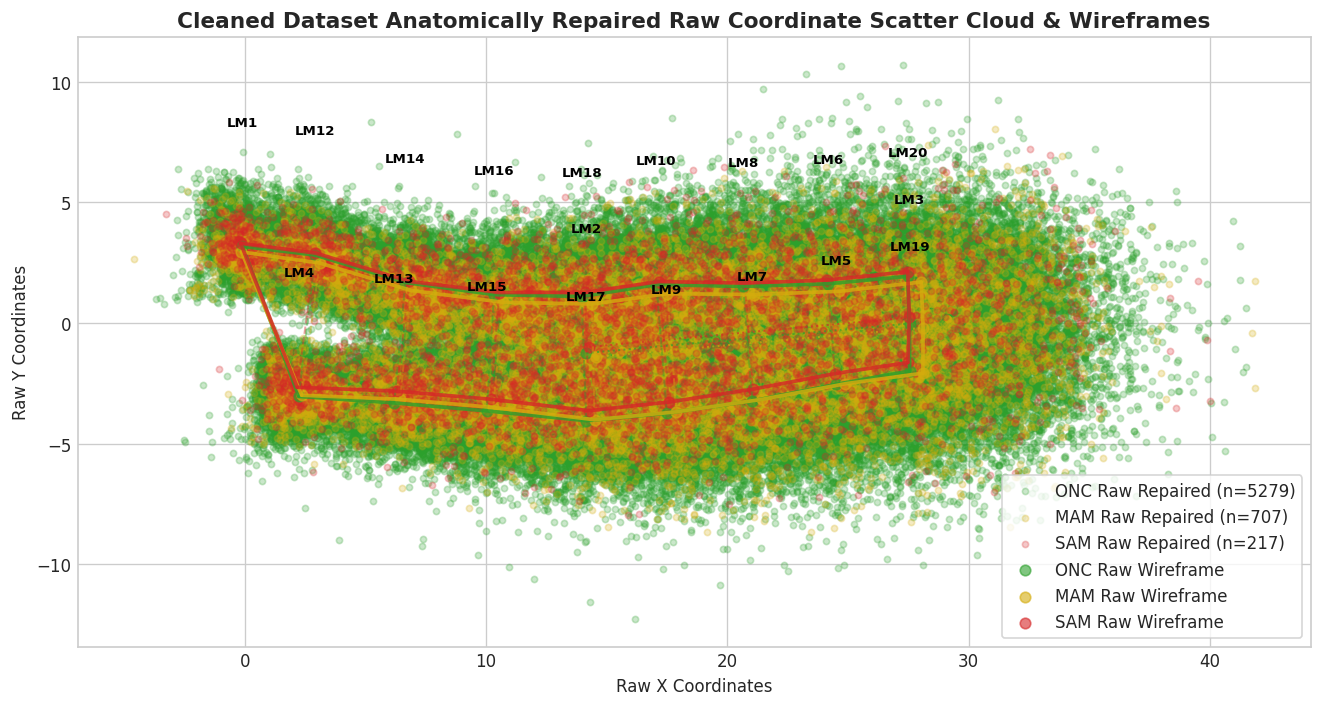

In [21]:
# 11.3 Repaired Raw Coordinate Clean Dataset Scatter Plot with Consensus Wireframe Connections
raw_x_cols = [f'X{lid}' for lid in landmark_ids]
raw_y_cols = [f'Y{lid}' for lid in landmark_ids]

fig, ax = plt.subplots(figsize=(14, 6))

# Scatter plot raw repaired coordinates for clean dataset
for cls in classes_list:
    mask = (df_final_clean['Class_Type'] == cls)
    cls_rx = df_final_clean.loc[mask, raw_x_cols].values.flatten()
    cls_ry = df_final_clean.loc[mask, raw_y_cols].values.flatten()
    ax.scatter(cls_rx, cls_ry, color=palette[cls], alpha=0.25, s=14, label=f"{cls.upper()} Raw Repaired (n={mask.sum()})", zorder=2)

# Compute mean raw repaired shape per class for wireframe overlay
raw_mean_shapes = {}
for cls in classes_list:
    mask = (df_final_clean['Class_Type'] == cls)
    m_rx = df_final_clean.loc[mask, raw_x_cols].mean().values
    m_ry = df_final_clean.loc[mask, raw_y_cols].mean().values
    raw_mean_shapes[cls] = np.column_stack([m_rx, m_ry])
    plot_arm_wireframe(ax, raw_mean_shapes[cls], color=palette[cls], label=f"{cls.upper()} Raw Wireframe", lw_solid=2.2, lw_dashed=1.2, s=40, show_labels=False)

# Annotate landmark numbers on raw ONC baseline
for lid in landmark_ids:
    idx = id_to_idx[lid]
    ax.text(raw_mean_shapes['onc'][idx, 0], raw_mean_shapes['onc'][idx, 1] + 5.0, f"LM{lid}", fontsize=8, fontweight='bold', color='black', ha='center', zorder=10)

ax.set_title("Cleaned Dataset Anatomically Repaired Raw Coordinate Scatter Cloud & Wireframes", fontsize=13, fontweight='bold')
ax.set_xlabel("Raw X Coordinates")
ax.set_ylabel("Raw Y Coordinates")
ax.legend(loc='lower right', frameon=True, facecolor='white')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()
